# Capítulo 10 — Ajustes lineares, covariância e geometria da informação
**Igor Stellet · Estatística Bayesiana · 2026.2**

Um experimento fornece medidas com incertezas; um modelo transforma parâmetros em previsões. **Como essas incertezas se propagam para os parâmetros e quais combinações o experimento consegue medir melhor?** Esta pergunta conecta o ajuste linear, as matrizes de covariância, as elipses e a matriz de Fisher.

O notebook está organizado da seguinte forma:

1. Construir um modelo linear e a likelihood, começando por uma amplitude de sinal.
2. Entender a covariância dos erros e obter a likelihood gaussiana geral.
3. Resolver um ajuste e encontrar a posterior completa dos parâmetros.
4. Interpretar as elipses, os eixos principais e o conteúdo de probabilidade.
5. Marginalizar, fixar parâmetros, combinar experimentos e acrescentar priors.
6. Mudar de variáveis e compreender Fisher como curvatura e como métrica.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, linalg, optimize, special
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 220,
                     'font.size': 11, 'axes.titlesize': 12,
                     'legend.fontsize': 9, 'grid.alpha': .2,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})
AZUL, VERDE, OURO, ROXO, VERMELHO = '#2878B5', '#27856D', '#B58618', '#8055A3', '#BD5254'
SALVAR_ARQUIVOS = False
BASE = Path.cwd()
PASTA_FIGURAS = BASE / 'figuras' / 'capitulo_10'
PASTA_TABELAS = BASE / 'tabelas' / 'capitulo_10'
verificacoes, figuras = [], []

def verificar(nome, condicao):
    if not np.all(condicao):
        raise AssertionError(nome)
    verificacoes.append(nome)

def figura(fig, nome):
    figuras.append(nome)
    if SALVAR_ARQUIVOS:
        PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
        for ext in ('png', 'pdf'):
            fig.savefig(PASTA_FIGURAS / f'{nome}.{ext}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def tabela(df, nome=None, casas=5):
    display(df.round(casas))
    if SALVAR_ARQUIVOS and nome:
        PASTA_TABELAS.mkdir(parents=True, exist_ok=True)
        df.to_csv(PASTA_TABELAS / f'{nome}.csv', index=False)

def correlacao(C):
    s = np.sqrt(np.diag(C))
    return C / np.outer(s, s)

def curva_elipse(media, C, prob=.682689492, pontos=600):
    """Fronteira da região gaussiana bidimensional de probabilidade prob."""
    vals, vet = np.linalg.eigh(C)
    if np.any(vals <= 0):
        raise ValueError('A covariância precisa ser definida positiva.')
    ang = np.linspace(0, 2*np.pi, pontos)
    circulo = np.array([np.cos(ang), np.sin(ang)])
    return np.asarray(media)[:, None] + vet @ (np.sqrt(stats.chi2.ppf(prob, 2)*vals)[:, None]*circulo)

def desenhar_elipse(ax, media, C, cor=AZUL, label=None, prob=.682689492, **kw):
    e = curva_elipse(media, C, prob)
    ax.plot(e[0], e[1], color=cor, label=label, **kw)
    return e

def ajuste_linear(G, d, E):
    """GLS por branqueamento e mínimos quadrados; E conhecida, posto completo."""
    L = np.linalg.cholesky(E)
    Gw = linalg.solve_triangular(L, G, lower=True)
    dw = linalg.solve_triangular(L, d, lower=True)
    A, _, posto, _ = np.linalg.lstsq(Gw, dw, rcond=None)
    if posto != G.shape[1]:
        raise ValueError('As funções de base precisam ser linearmente independentes.')
    F = Gw.T @ Gw
    C = linalg.solve(F, np.eye(F.shape[0]), assume_a='pos')
    r = dw-Gw@A
    return {'A': A, 'F': F, 'C': C, 'chi2': r@r,
            'L': L, 'Gw': Gw, 'dw': dw, 'h': Gw.T@dw}

print('Exportação opcional:', SALVAR_ARQUIVOS)

Exportação opcional: False


## 1. Linearidade: quais quantidades estamos estimando?

Escrevemos cada medida como
$$
d_i=f(x_i;\boldsymbol A)+\varepsilon_i,
\qquad f(x_i;\boldsymbol A)=\sum_{\alpha=1}^{M}A_\alpha g_\alpha(x_i).
$$
Os $x_i$ são entradas conhecidas do experimento; os $A_\alpha$ são parâmetros a inferir; as funções $g_\alpha$ são conhecidas. **Linearidade se refere à dependência em $\boldsymbol A$.** Uma função de $x$ pode ser curva e continuar linear nos parâmetros.

| Modelo | Parâmetros lineares | O que precisa estar conhecido |
|---|---|---|
| $a+bx$ | $a,b$ | entradas $x_i$ |
| $a+bx+cx^2$ | $a,b,c$ | entradas $x_i$ |
| $A\cos\omega t+B\sin\omega t$ | $A,B$ | frequência $\omega$ |
| $T\exp[-(\nu-\nu_0)^2/(2s_L^2)]$ | amplitude $T$ | centro $\nu_0$ e largura $s_L$ |

Se também estimarmos $\omega$, $\nu_0$ ou $s_L$, a dependência nesses parâmetros será não linear. É possível tratar um mesmo modelo como linear em um subconjunto e não linear no restante.

Para organizar as contas, reunimos as medidas em $\boldsymbol D$ e avaliamos as funções de base em uma **matriz de desenho** $G$:
$$
\boldsymbol f=G\boldsymbol A,\qquad
G_{i\alpha}=g_\alpha(x_i).
$$
Assim, $\boldsymbol D$ e $\boldsymbol f$ têm $N$ componentes, $\boldsymbol A$ tem $M$, e $G$ tem dimensão $N\times M$. Cada **coluna de $G$ é um padrão de sinal**; os parâmetros dizem quanto de cada padrão aparece nos dados. No modelo de reta, as colunas são $\boldsymbol 1$ e $\boldsymbol x$.

### Uma amplitude de linha espectral: a primeira posterior

Suponhamos $d_i=Tg_i+\varepsilon_i$, com $\varepsilon_i\sim\mathcal N(0,\sigma^2)$ independentes e $g_i$ um perfil de linha conhecido. Pela mudança $\varepsilon_i=d_i-Tg_i$, cujo jacobiano em relação ao dado é unitário,
$$
\mathcal L(T)=p(\boldsymbol D\mid T)
=(2\pi\sigma^2)^{-N/2}
\exp\!\left[-\frac{1}{2\sigma^2}\sum_i(d_i-Tg_i)^2\right].
$$
O produto vale pela independência dos erros. Expandimos o quadrado e completamos:
$$
\begin{aligned}
Q(T)&=\boldsymbol D^T\boldsymbol D-2T\boldsymbol g^T\boldsymbol D
       +T^2\boldsymbol g^T\boldsymbol g\\
&=Q(\widehat T)+(\boldsymbol g^T\boldsymbol g)(T-\widehat T)^2,\\
\widehat T&=\frac{\boldsymbol g^T\boldsymbol D}{\boldsymbol g^T\boldsymbol g},
\qquad \sigma_T^2=\frac{\sigma^2}{\boldsymbol g^T\boldsymbol g}.
\end{aligned}
$$
Com prior constante em $T\in\mathbb R$, a posterior própria é
$T\mid\boldsymbol D\sim\mathcal N(\widehat T,\sigma_T^2)$.
Uma prior uniforme finita muito mais larga que essa curva produz a mesma forma na região relevante. Restrições físicas, como $T\geq0$, exigem normalizar no suporte permitido.

**Intuição:** $\boldsymbol g^T\boldsymbol D$ procura o padrão da linha nos dados. O denominador calibra a resposta desse padrão. Pontos em que $g_i$ é grande contribuem mais à medida da amplitude; vários pontos precisos reduzem $\sigma_T$. Uma única medida independente de ruído conhecido continua fornecendo uma likelihood com largura finita.

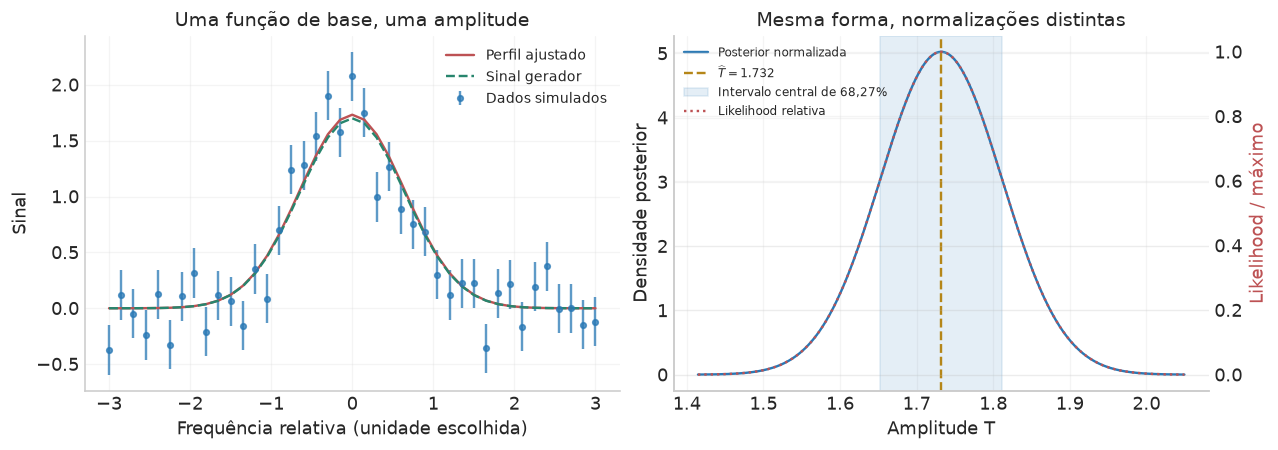

T = 1.7320 ± 0.0794; valor gerador = 1.70.


In [2]:
rng_linha = np.random.default_rng(1010)
nu = np.linspace(-3, 3, 41)
g = np.exp(-nu**2/(2*.65**2))
sigma_linha, T_real = .22, 1.7
d_linha = T_real*g + rng_linha.normal(0, sigma_linha, nu.size)
T_hat = g@d_linha/(g@g)
s_T = sigma_linha/np.sqrt(g@g)
tg = np.linspace(T_hat-4*s_T, T_hat+4*s_T, 500)
qg = np.sum((d_linha[:, None]-g[:, None]*tg)**2, axis=0)
relL = np.exp(-.5*(qg-np.sum((d_linha-T_hat*g)**2))/sigma_linha**2)
postT = stats.norm.pdf(tg, T_hat, s_T)
verificar('Completar o quadrado no exemplo de amplitude',
          np.allclose(qg, np.sum((d_linha-T_hat*g)**2)+(g@g)*(tg-T_hat)**2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
ax[0].errorbar(nu, d_linha, yerr=sigma_linha, fmt='o', ms=3.5, color=AZUL, alpha=.75, label='Dados simulados')
ax[0].plot(nu, T_hat*g, color=VERMELHO, label='Perfil ajustado')
ax[0].plot(nu, T_real*g, '--', color=VERDE, label='Sinal gerador')
ax[0].set(xlabel='Frequência relativa (unidade escolhida)', ylabel='Sinal', title='Uma função de base, uma amplitude')
ax[0].legend()
ax[1].plot(tg, postT, color=AZUL, label='Posterior normalizada')
ax[1].axvline(T_hat, color=OURO, ls='--', label=fr'$\widehat T={T_hat:.3f}$')
ax[1].axvspan(T_hat-s_T, T_hat+s_T, color=AZUL, alpha=.12, label='Intervalo central de 68,27%')
axr = ax[1].twinx()
axr.plot(tg, relL, ':', color=VERMELHO, label='Likelihood relativa')
axr.set_ylabel('Likelihood / máximo', color=VERMELHO)
ax[1].set(xlabel='Amplitude T', ylabel='Densidade posterior', title='Mesma forma, normalizações distintas')
h1,l1=ax[1].get_legend_handles_labels()
h2,l2=axr.get_legend_handles_labels()
ax[1].legend(h1+h2,l1+l2,loc='upper left', fontsize=7.5)
figura(fig, '01_amplitude_linha')
print(f'T = {T_hat:.4f} ± {s_T:.4f}; valor gerador = {T_real:.2f}.')

A likelihood acima é função de $T$ para **dados fixos**. Sua normalização original é sobre os dados possíveis. A posterior é uma densidade em $T$ e integra a unidade nesse parâmetro. A prior constante faz as formas coincidirem; o fator de normalização e a interpretação continuam distintos.


## 2. Covariância: como as flutuações se movem em conjunto?

Para um vetor aleatório $\boldsymbol X$ de média $\boldsymbol\mu$, definimos
$$
\Sigma_{ij}=\mathbb E[(X_i-\mu_i)(X_j-\mu_j)],
\qquad
\Sigma=\mathbb E[(\boldsymbol X-\boldsymbol\mu)(\boldsymbol X-\boldsymbol\mu)^T].
$$
Na diagonal ficam as variâncias. Fora dela, produtos de desvios com o mesmo sinal contribuem positivamente; desvios com sinais opostos contribuem negativamente. A média desses produtos mede o movimento conjunto.

A covariância tem unidades de $X_iX_j$. Para comparar a intensidade da associação, padronizamos $Z_i=(X_i-\mu_i)/s_i$, onde $s_i^2=\Sigma_{ii}>0$. Se $S=\operatorname{diag}(s_1,\ldots,s_N)$,
$$
R=\operatorname{Cov}(\boldsymbol Z)=S^{-1}\Sigma S^{-1},
\qquad R_{ij}=\rho_{ij}=\frac{\Sigma_{ij}}{s_i s_j}.
$$
**A matriz de correlação é a covariância das variáveis padronizadas.** Sua diagonal vale 1. A covariância carrega a escala física; a correlação descreve a associação linear em unidades de desvios padrão.

Algumas propriedades saem diretamente da definição:
$$
\Sigma^T=\Sigma,\qquad
\boldsymbol v^T\Sigma\boldsymbol v
=\operatorname{Var}(\boldsymbol v^T\boldsymbol X)\geq0,
\qquad
\operatorname{Cov}(B\boldsymbol X+\boldsymbol c)=B\Sigma B^T.
$$
A última identidade segue ao escrever o desvio como $B(\boldsymbol X-\boldsymbol\mu)$ e levar $B$ para fora da esperança. Também usamos
$\operatorname{Cov}(\boldsymbol X,\boldsymbol Y)=\mathbb E[(\boldsymbol X-\mu_X)(\boldsymbol Y-\mu_Y)^T]$; suas dimensões podem ser diferentes, e a covariância cruzada tem tamanho $N_X\times N_Y$.

A covariância é sempre **semidefinida positiva**. Para uma densidade gaussiana usual em todo o espaço e para usar sua inversa, exigiremos que seja **definida positiva**. Um modo de variância zero corresponde a uma restrição exata. Para variáveis conjuntamente gaussianas, covariância nula implica independência; em distribuições gerais, ela informa somente ausência de associação linear.

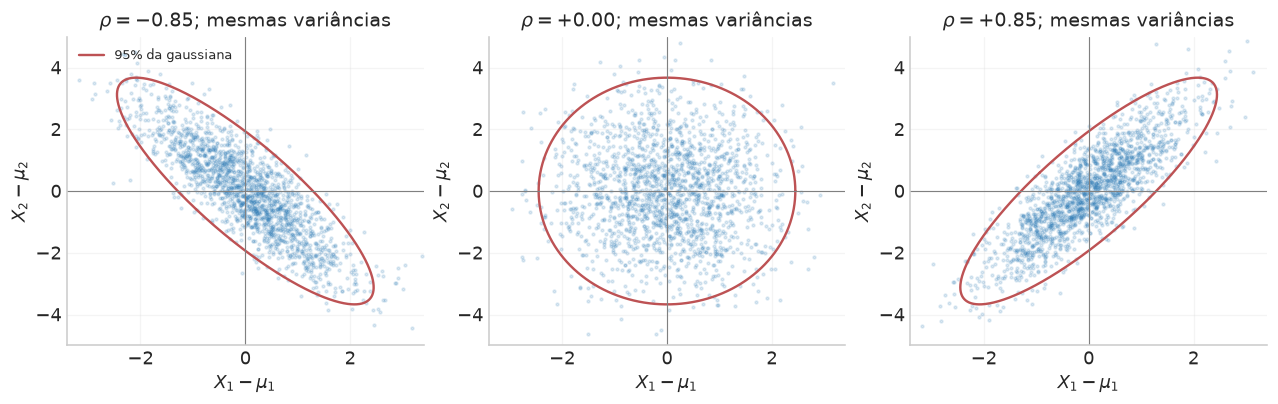

In [3]:
rng_cov = np.random.default_rng(2010)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
for ax, rho in zip(axs, [-.85, 0., .85]):
    Sigma = np.array([[1., 1.5*rho], [1.5*rho, 1.5**2]])
    am = rng_cov.multivariate_normal([0, 0], Sigma, 1800)
    ax.scatter(am[:, 0], am[:, 1], s=3, alpha=.15, color=AZUL)
    desenhar_elipse(ax, [0, 0], Sigma, cor=VERMELHO, prob=.95, label='95% da gaussiana')
    ax.axhline(0, color='gray', lw=.7); ax.axvline(0, color='gray', lw=.7)
    ax.set(xlabel=r'$X_1-\mu_1$', ylabel=r'$X_2-\mu_2$',
           xlim=(-3.4, 3.4), ylim=(-5, 5), title=fr'$\rho={rho:+.2f}$; mesmas variâncias')
axs[0].legend(loc='upper left', fontsize=8)
figura(fig, '02_intuicao_covariancia')

### Uma origem física de correlação: erro de referência compartilhado

Em uma calibração, cada leitura pode ter um erro próprio $\eta_i$ e um deslocamento comum $c$:
$$
\varepsilon_i=\eta_i+c,\qquad
\eta_i\sim\mathcal N(0,s_i^2),\quad c\sim\mathcal N(0,\tau^2),
$$
com todos os $\eta_i$ independentes entre si e de $c$. Ao propagar a incerteza no deslocamento,
$$
E_{ij}=\mathbb E[(\eta_i+c)(\eta_j+c)]
=s_i^2\delta_{ij}+\tau^2,
\qquad E=\operatorname{diag}(s_i^2)+\tau^2\boldsymbol 1\boldsymbol 1^T.
$$
Cada realização repete a calibração inteira com um novo $c$. Condicionando no valor exato de $c$, os erros próprios continuam independentes; **marginalizar a incerteza compartilhada produz a correlação**. O deslocamento comum consegue imitar parte do intercepto, de modo que repetir leituras reduz o ruído próprio e preserva a incerteza da referência.

Aqui $E$ será a **covariância dos erros/dados condicionada nos parâmetros**. A posterior dos parâmetros terá outra matriz, $C$. Essa distinção é importante: uma matriz vive no espaço de $N$ dados; a outra, no espaço de $M$ parâmetros.

Se conhecemos o mecanismo de ruído, podemos calcular $E$. Quando usamos $K$ catálogos simulados independentes, estimamos
$$
\widehat E=\frac1{K-1}\sum_{k=1}^K
(\boldsymbol D^{(k)}-\overline{\boldsymbol D})
(\boldsymbol D^{(k)}-\overline{\boldsymbol D})^T.
$$
O tamanho de uma matriz estimada a partir de mocks depende do número de componentes de cada catálogo. Sua precisão depende do número de **realizações independentes**, e flutuações usuais de estimação decrescem como $K^{-1/2}$. Uma única lista de resíduos exige hipóteses adicionais para estimar uma matriz arbitrária. Neste capítulo trataremos $E$ como conhecida; propagar a incerteza em $\widehat E$ acrescenta outra etapa ao modelo.

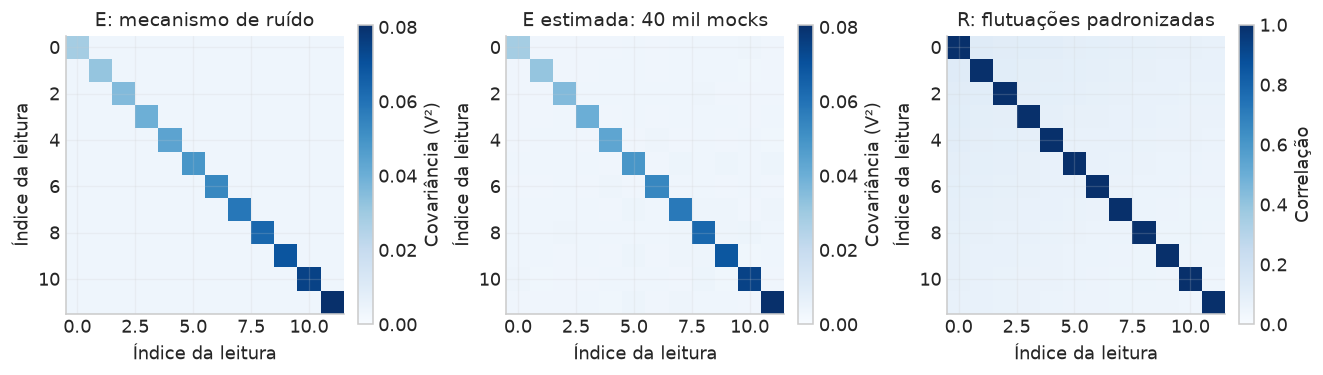

In [4]:
# Exemplo recorrente: entrada x adimensional e saída em volts.
x = np.linspace(.3, 5.1, 12)
G = np.column_stack([np.ones(x.size), x])
A_real = np.array([.8, 1.25])  # a e b em V, pois x é adimensional.
s = .15 + .025*x
s_ref = .06
E = np.diag(s**2) + s_ref**2*np.ones((x.size, x.size))
L = np.linalg.cholesky(E)
rng_cal = np.random.default_rng(3010)
c_real = rng_cal.normal(0, s_ref)
d = G@A_real + rng_cal.normal(0, s) + c_real

rng_mocks = np.random.default_rng(3011)
mocks = rng_mocks.normal(size=(40000, x.size))@L.T
E_mock = np.cov(mocks, rowvar=False, ddof=1)
verificar('Covariância dos mocks reproduz a estrutura geradora',
          np.linalg.norm(E_mock-E)/np.linalg.norm(E) < .035)
fig, axs = plt.subplots(1, 3, figsize=(11.4, 3.4), constrained_layout=True)
for ax, mat, titulo in zip(axs, [E, E_mock, correlacao(E)],
                           ['E: mecanismo de ruído', 'E estimada: 40 mil mocks', 'R: flutuações padronizadas']):
    im = ax.imshow(mat, cmap='Blues', vmin=0, vmax=1 if titulo.startswith('R:') else E.max())
    ax.set(title=titulo, xlabel='Índice da leitura', ylabel='Índice da leitura')
    fig.colorbar(im, ax=ax, shrink=.82, label='Correlação' if titulo.startswith('R:') else 'Covariância (V²)')
figura(fig, '03_covariancia_dados_mocks')

## 3. Da gaussiana independente à likelihood geral

Assumindo que os erros têm uma distribuição gaussiana, de média 0, podemos definir a matriz de covariãncia $E$dos erros como:

$$
E_{ij} = Cov(\epsilon _i, \epsilon_j) = \mathbb{E}[\epsilon _i\epsilon_j]
$$
Comecemos por $\boldsymbol z\sim\mathcal N(\boldsymbol0,I_N)$, a variável padronizada, com componentes independentes, pode ser descrita por $\boldsymbol\varepsilon=L\boldsymbol z$. Dessa definição, podemos mostrar que, para $E$ definida positiva, existe a fatoração de Cholesky $E=LL^T$. Escrevemos
$$
\boldsymbol\varepsilon=L\boldsymbol z,
\qquad \boldsymbol z=L^{-1}(\boldsymbol D-\boldsymbol f).
$$
Partindo da distribuição gaussiana de $Z$, podemos fazer uma transformação de variáveis para obter a distribuição dos erros. A transformação tem jacobiano
$|\partial\boldsymbol z/\partial\boldsymbol D|=1/|\det L|=1/\sqrt{\det E}$.
Além disso,
$$
\boldsymbol z^T\boldsymbol z
=(\boldsymbol D-\boldsymbol f)^TL^{-T}L^{-1}(\boldsymbol D-\boldsymbol f)
=(\boldsymbol D-\boldsymbol f)^TE^{-1}(\boldsymbol D-\boldsymbol f).
$$
Logo,
$$
\boxed{\mathcal L(\boldsymbol A)=
\frac{\exp[-\chi^2(\boldsymbol A)/2]}{(2\pi)^{N/2}\sqrt{\det E}},\qquad
\chi^2(\boldsymbol A)=(\boldsymbol D-G\boldsymbol A)^TE^{-1}(\boldsymbol D-G\boldsymbol A).}
$$
A normalização sai da mesma mudança de variáveis que produz o expoente. Para erros independentes, $E=\operatorname{diag}(\sigma_i^2)$ e
$\chi^2=\sum_i(d_i-f_i)^2/\sigma_i^2$. Para erros IID, $E=\sigma^2I$ e $\chi^2=Q/\sigma^2$.

**Intuição geométrica:** $E^{-1}$ mede o custo de um resíduo. Uma flutuação coletiva comum no mecanismo de ruído recebe um custo menor que uma flutuação improvável de mesmo comprimento euclidiano. O branqueamento $L^{-1}$ transforma essas distâncias ponderadas em distâncias euclidianas.

A forma gaussiana também maximiza a entropia diferencial em $\mathbb R^N$ quando fixamos **a média e a matriz de covariância**, com esses momentos existentes. Saber apenas que a variância é finita deixa seus valores por especificar. Podemos adotar outros modelos de ruído; a posterior gaussiana exata deste capítulo usa especificamente a likelihood gaussiana e o modelo linear.

A definição da forma quadrática $\chi^2$ também serve para $\boldsymbol f(\boldsymbol\theta)$ não linear. A linearidade permitirá resolver o ajuste e obter sua distribuição exatamente. Se $E=E(\boldsymbol\theta)$, o termo $\log\det E$ também varia:
$$
-2\log\mathcal L=N\log(2\pi)+\log\det E(\boldsymbol\theta)+\chi^2(\boldsymbol\theta).
$$
Nesse caso a maximização usa a expressão completa.

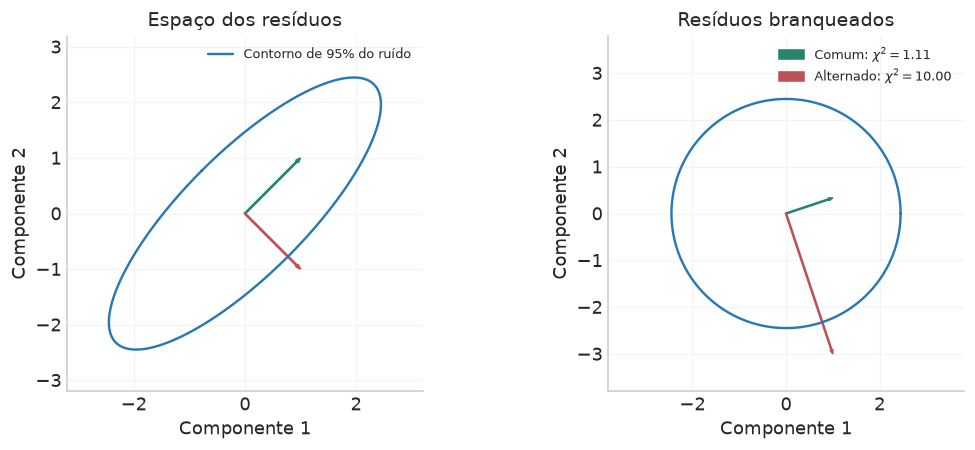

,Resíduo,Norma euclidiana²,Distância ponderada χ²
0,Comum,2.0,1.11111
1,Alternado,2.0,10.00000


In [5]:
# Dois resíduos de mesmo tamanho euclidiano: comum e alternado.
E2 = np.array([[1., .8], [.8, 1.]])
L2 = np.linalg.cholesky(E2)
residuos = np.array([[1., 1.], [1., -1.]])
brancos = linalg.solve_triangular(L2, residuos.T, lower=True).T
q2 = np.sum(brancos**2, axis=1)
verificar('Quadrática e branqueamento são equivalentes',
          np.allclose(q2, np.einsum('ni,ij,nj->n', residuos, np.linalg.inv(E2), residuos)))
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.8), constrained_layout=True)
desenhar_elipse(axs[0], [0, 0], E2, prob=.95, label='Contorno de 95% do ruído')
desenhar_elipse(axs[1], [0, 0], np.eye(2), prob=.95)
for r, z, cor, lab, q in zip(residuos, brancos, [VERDE, VERMELHO], ['Comum', 'Alternado'], q2):
    axs[0].arrow(0, 0, *r, color=cor, width=.02, length_includes_head=True)
    axs[1].arrow(0, 0, *z, color=cor, width=.02, length_includes_head=True,
                 label=fr'{lab}: $\chi^2={q:.2f}$')
for ax, title, lim in zip(axs, ['Espaço dos resíduos', 'Resíduos branqueados'], [3.2, 3.8]):
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=title, xlabel='Componente 1', ylabel='Componente 2', aspect='equal')
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
figura(fig, '04_branqueamento_residuos')
tabela(pd.DataFrame({'Resíduo': ['Comum', 'Alternado'], 'Norma euclidiana²': np.sum(residuos**2, axis=1),
                     'Distância ponderada χ²': q2}), 'residuos_ponderados')

O resíduo comum acompanha a direção em que os erros já costumam variar juntos. O alternado exige uma diferença grande entre leituras fortemente correlacionadas, por isso tem um $\chi^2$ maior.


## 4. Best fit: projetar os dados sobre os padrões do modelo

Com $W=E^{-1}$ fixa e simétrica, abrimos a quadrática:
$$
\begin{aligned}
\chi^2(\boldsymbol A)
&=(\boldsymbol D-G\boldsymbol A)^TW(\boldsymbol D-G\boldsymbol A)\\
&=\boldsymbol D^TW\boldsymbol D
 -2\boldsymbol A^TG^TW\boldsymbol D
 +\boldsymbol A^TG^TWG\boldsymbol A.
\end{aligned}
$$
Definimos $\boldsymbol h=G^TW\boldsymbol D$ e $\Psi=G^TWG$. Derivando em cada componente,
$$
\frac{\partial\chi^2}{\partial A_\alpha}
=-2h_\alpha+2\sum_\beta\Psi_{\alpha\beta}A_\beta.
$$
Igualar o gradiente a zero dá as **equações normais**:
$$
\Psi\widehat{\boldsymbol A}=\boldsymbol h,
\qquad
\boxed{\widehat{\boldsymbol A}=(G^TE^{-1}G)^{-1}G^TE^{-1}\boldsymbol D
=\Psi^{-1}\boldsymbol h.}
$$
$\boldsymbol h$ tem $M$ componentes e mede a sobreposição ponderada dos dados com cada padrão. $\Psi$ é $M\times M$ e mede a sobreposição dos próprios padrões. Se eles se parecem, o mesmo sinal pode ser explicado por combinações diferentes de amplitudes. Multiplicar por $\Psi^{-1}$ desfaz essa mistura.

No caso IID, $\Psi=\psi/\sigma^2$, $\psi=G^TG$, e
$\widehat{\boldsymbol A}=\psi^{-1}G^T\boldsymbol D$; o fator comum de ruído cancela no ponto ótimo, embora determine a largura da posterior.

Para visualizar a projeção, escrevemos $\widetilde G=L^{-1}G$ e $\widetilde{\boldsymbol D}=L^{-1}\boldsymbol D$. As equações normais viram
$$
\widetilde G^T(\widetilde{\boldsymbol D}-\widetilde G\widehat{\boldsymbol A})=0.
$$
O resíduo branqueado é ortogonal a todas as colunas de $\widetilde G$. O melhor modelo é a projeção de $\widetilde{\boldsymbol D}$ sobre o subespaço gerado por essas colunas. É a mesma ideia da decomposição de um vetor em uma parte paralela a um plano e uma parte perpendicular.

**Condições:** $E$ conhecida e definida positiva; $G$ com posto de coluna completo; entradas tratadas como conhecidas. Uma degenerescência exata entre bases torna $\Psi$ singular: os dados medem somente certas combinações. Uma prior própria pode completar a informação. Em código, resolver sistemas e usar QR/SVD ou mínimos quadrados branqueados evita formar inversas desnecessárias; `ajuste_linear` usa esse último caminho.

In [7]:
cal = ajuste_linear(G, d, E)
A_hat, F, C = cal['A'], cal['F'], cal['C']
verificar('Equações normais da calibração', np.allclose(F@A_hat, cal['h']))
verificar('Resíduo ortogonal ao espaço do modelo',
          np.allclose(cal['Gw'].T@(cal['dw']-cal['Gw']@A_hat), 0, atol=1e-11))
verificar('Solução GLS coincide com mínimos quadrados branqueados',
          np.allclose(A_hat, np.linalg.solve(F, cal['h'])))
tabela(pd.DataFrame(G, columns=['g₁ = 1', 'g₂ = x']).head(), 'matriz_desenho')
tabela(pd.DataFrame(F, index=['a', 'b'], columns=['a', 'b']), 'precisao_calibracao')
tabela(pd.DataFrame({'Parâmetro': ['a (V)', 'b (V)'], 'Gerador': A_real,
                     'Best fit': A_hat, 'Desvio posterior': np.sqrt(np.diag(C))}), 'ajuste_calibracao')
print('h =', np.round(cal['h'], 5))
print(f'χ² mínimo = {cal["chi2"]:.4f}; N-M = {len(x)-2}; ρ(a,b) = {correlacao(C)[0,1]:.4f}.')
display(Markdown(f'**Leitura do ajuste:** o intercepto foi estimado em **{A_hat[0]:.3f} ± {np.sqrt(C[0,0]):.3f} V**, e o ganho em **{A_hat[1]:.3f} ± {np.sqrt(C[1,1]):.3f} V**. A correlação de **{correlacao(C)[0,1]:.3f}** quantifica a compensação entre altura e inclinação. As incertezas citadas são desvios marginais da posterior.'))

,g₁ = 1,g₂ = x
0,1.0,0.30000
1,1.0,0.73636
2,1.0,1.17273
3,1.0,1.60909
4,1.0,2.04545


,a,b
a,139.12138,301.78240
b,301.78240,1254.72067


,Parâmetro,Gerador,Best fit,Desvio posterior
0,a (V),0.80,1.00181,0.12259
1,b (V),1.25,1.19424,0.04082


h = [ 499.77321 1800.7644 ]
χ² mínimo = 13.0820; N-M = 10; ρ(a,b) = -0.7223.


**Leitura do ajuste:** o intercepto foi estimado em **1.002 ± 0.123 V**, e o ganho em **1.194 ± 0.041 V**. A correlação de **-0.722** quantifica a compensação entre altura e inclinação. As incertezas citadas são desvios marginais da posterior.

### Do ponto ótimo à posterior completa

Escrevemos $\boldsymbol A=\widehat{\boldsymbol A}+\delta\boldsymbol A$ e
$\widehat{\boldsymbol r}=\boldsymbol D-G\widehat{\boldsymbol A}$. Então,
$$
\begin{aligned}
\chi^2(\widehat{\boldsymbol A}+\delta\boldsymbol A)
&=(\widehat{\boldsymbol r}-G\delta\boldsymbol A)^TW
 (\widehat{\boldsymbol r}-G\delta\boldsymbol A)\\
&=\chi^2_{\min}-2\delta\boldsymbol A^TG^TW\widehat{\boldsymbol r}
  +\delta\boldsymbol A^T\Psi\delta\boldsymbol A\\
&=\chi^2_{\min}+\delta\boldsymbol A^T\Psi\delta\boldsymbol A.
\end{aligned}
$$
O termo cruzado zera pelas equações normais. Com prior constante em $\mathbb R^M$, a posterior normalizada é
$$
\boxed{p(\boldsymbol A\mid\boldsymbol D)=
\frac{\sqrt{\det\Psi}}{(2\pi)^{M/2}}
\exp\!\left[-\frac12(\boldsymbol A-\widehat{\boldsymbol A})^T
\Psi(\boldsymbol A-\widehat{\boldsymbol A})\right],\qquad C=\Psi^{-1}.}
$$
A constante sai de diagonalizar $\Psi$ e integrar o produto de $M$ gaussianas. Faremos essa mudança em detalhe ao discutir os eixos principais. A prior constante imprópria serve aqui para estimação, pois a posterior é própria sob as condições acima; evidências entre modelos exigiriam normalizações de priors próprias. Uma prior uniforme finita produz uma gaussiana truncada, aproximadamente igual à expressão acima quando suas bordas ficam distantes.

Há também uma interpretação por propagação dos erros. Com
$B=(G^TWG)^{-1}G^TW$, temos $\widehat{\boldsymbol A}=B\boldsymbol D$ e, repetindo o experimento com parâmetros verdadeiros $\boldsymbol A_*$,
$$
\mathbb E[\widehat{\boldsymbol A}]=BG\boldsymbol A_*=\boldsymbol A_*,
\quad
\operatorname{Cov}(\widehat{\boldsymbol A})=BEB^T
=\Psi^{-1}G^TWEWG\Psi^{-1}=\Psi^{-1}.
$$
Neste problema especial, **a covariância da posterior com prior plana e a covariância amostral do estimador coincidem numericamente**. As interpretações continuam distintas: uma descreve a incerteza nos parâmetros dados os dados; a outra descreve a flutuação do estimador entre repetições.

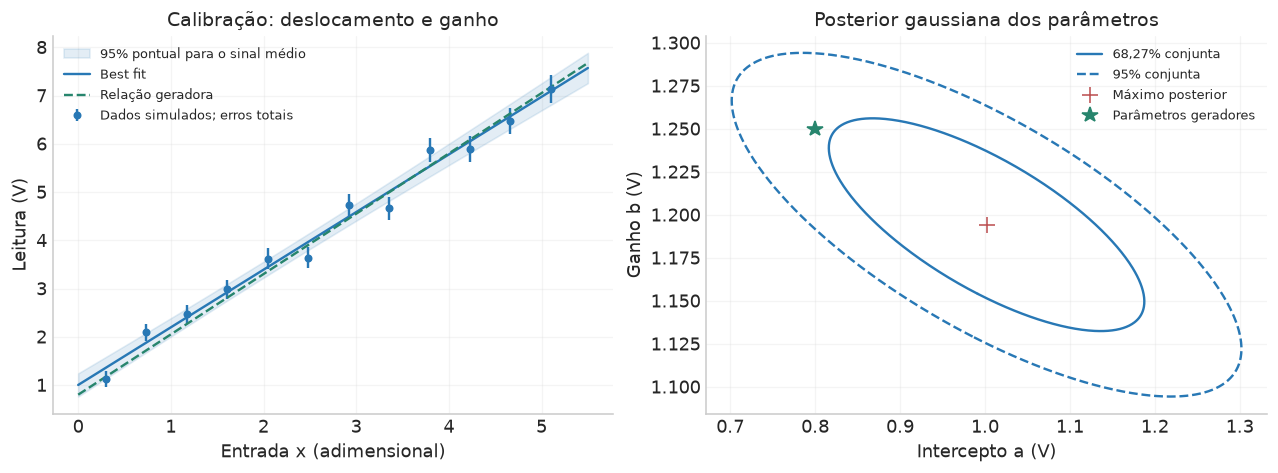

In [8]:
# Conferência da forma quadrática e da covariância propagada.
B = linalg.solve(F, linalg.solve(E, G, assume_a='pos').T, assume_a='pos')
verificar('Covariância dos parâmetros = B E Bᵀ', np.allclose(B@E@B.T, C))
delta = np.array([.15, -.08])
r_teste = d-G@(A_hat+delta)
verificar('Completar o quadrado multivariado',
          np.isclose(r_teste@linalg.solve(E, r_teste), cal['chi2']+delta@F@delta))
xplot = np.linspace(0, 5.5, 250)
Gp = np.column_stack([np.ones(xplot.size), xplot])
media_sinal = Gp@A_hat
sinal_sd = np.sqrt(np.einsum('ij,jk,ik->i', Gp, C, Gp))
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axs[0].errorbar(x, d, yerr=np.sqrt(np.diag(E)), fmt='o', color=AZUL, ms=4, label='Dados simulados; erros totais')
axs[0].fill_between(xplot, media_sinal-1.96*sinal_sd, media_sinal+1.96*sinal_sd, color=AZUL, alpha=.13, label='95% pontual para o sinal médio')
axs[0].plot(xplot, media_sinal, color=AZUL, label='Best fit')
axs[0].plot(xplot, Gp@A_real, '--', color=VERDE, label='Relação geradora')
axs[0].set(xlabel='Entrada x (adimensional)', ylabel='Leitura (V)', title='Calibração: deslocamento e ganho')
axs[0].legend(fontsize=8)
for p, estilo, lab in [(.682689492, '-', '68,27% conjunta'), (.95, '--', '95% conjunta')]:
    desenhar_elipse(axs[1], A_hat, C, prob=p, ls=estilo, label=lab)
axs[1].plot(*A_hat, '+', color=VERMELHO, ms=10, label='Máximo posterior')
axs[1].plot(*A_real, '*', color=VERDE, ms=10, label='Parâmetros geradores')
axs[1].set(xlabel='Intercepto a (V)', ylabel='Ganho b (V)', title='Posterior gaussiana dos parâmetros')
axs[1].legend(fontsize=8)
figura(fig, '05_calibracao_posterior')

A faixa no painel esquerdo usa
$\operatorname{Var}[f(x)\mid\boldsymbol D]=(1,x)C(1,x)^T$.
Ela descreve a incerteza **no sinal médio em cada $x$**. Uma previsão de nova leitura também propagaria o ruído dessa leitura e suas eventuais correlações com as anteriores. O intervalo de 95% desenhado é pontual em $x$; uma banda simultânea para toda a curva é outro objeto.

A correlação negativa no painel direito tem uma interpretação direta: aumentar o intercepto e reduzir o ganho pode preservar as previsões perto do centro das medidas. Essa compensação existe mesmo se os erros dos dados forem independentes. **Correlação entre parâmetros nasce também da sobreposição das funções de base**, através de $G^TE^{-1}G$.

,xᵢ,dᵢ,nᵢ,Erro da média
0,10.0,0.50,14,0.76064
1,20.0,4.67,3,1.64317
2,30.0,6.25,25,0.56921
3,40.0,10.00,2,2.01246
4,50.0,13.50,3,1.64317
5,60.0,13.70,22,0.60678
6,70.0,17.50,5,1.27279
7,80.0,23.00,2,2.01246


,Parâmetro,Best fit,Desvio marginal
0,a,-2.05452,0.70041
1,b,0.27535,0.01565


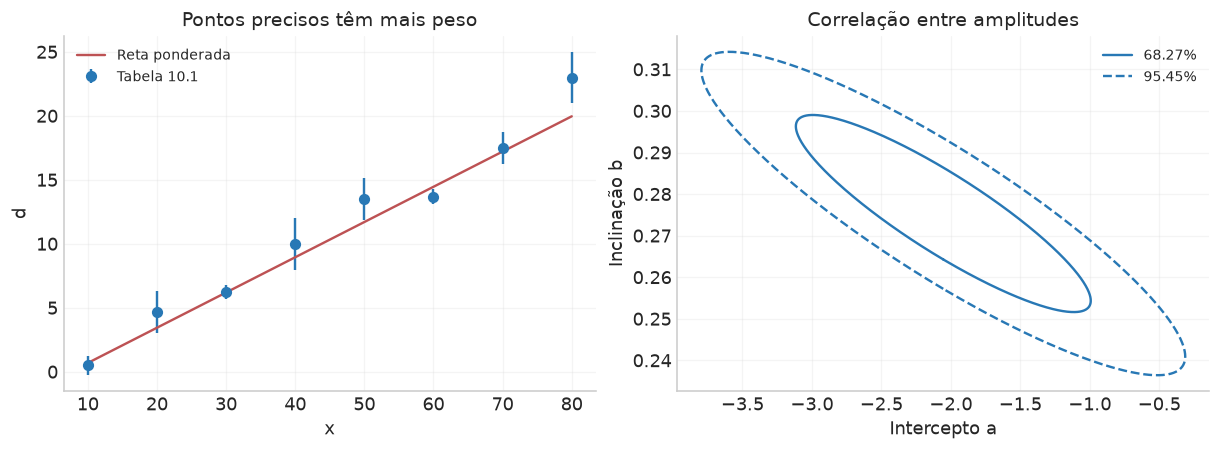

ρ(a,b), com a matriz sem arredondar = -0.884728


In [9]:
xg = np.arange(10., 81., 10.)
dg = np.array([.5, 4.67, 6.25, 10., 13.5, 13.7, 17.5, 23.])
ng = np.array([14, 3, 25, 2, 3, 22, 5, 2])
Gg = np.column_stack([np.ones(xg.size), xg])
Eg = np.diag(8.1/ng)
greg = ajuste_linear(Gg, dg, Eg)
tabela(pd.DataFrame({'xᵢ': xg, 'dᵢ': dg, 'nᵢ': ng, 'Erro da média': np.sqrt(np.diag(Eg))}), 'gregory_dados')
tabela(pd.DataFrame({'Parâmetro': ['a', 'b'], 'Best fit': greg['A'],
                     'Desvio marginal': np.sqrt(np.diag(greg['C']))}), 'gregory_resultado')
verificar('Matriz do exemplo do Gregory',
          np.allclose(8.1*greg['F'], [[76, 3010], [3010, 152300]]))
verificar('Best fit reproduz Gregory na precisão publicada',
          np.allclose(greg['A'], [-2.054, .275], atol=.001))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
axs[0].errorbar(xg, dg, yerr=np.sqrt(np.diag(Eg)), fmt='o', color=AZUL, label='Tabela 10.1')
axs[0].plot(xg, Gg@greg['A'], color=VERMELHO, label='Reta ponderada')
axs[0].set(xlabel='x', ylabel='d', title='Pontos precisos têm mais peso');axs[0].legend()
for p, st in [(.682689492, '-'), (.954499736, '--')]:
    desenhar_elipse(axs[1], greg['A'], greg['C'], prob=p, ls=st, label=f'{100*p:.2f}%')
axs[1].set(xlabel='Intercepto a', ylabel='Inclinação b', title='Correlação entre amplitudes')
axs[1].legend()
figura(fig, '06_gregory_tabela_10_1')
print('ρ(a,b), com a matriz sem arredondar =', round(correlacao(greg['C'])[0,1], 6))

## 5. Quando o nosso $\chi^2$ segue uma distribuição qui-quadrado?

Dar o nome $\chi^2$ à soma ponderada especifica uma **estatística**. Sua distribuição depende do modelo gerador e da etapa da análise. Aqui conseguimos três resultados exatos.

### 5.1 Avaliar os parâmetros verdadeiros: $N$ graus de liberdade

Se $\boldsymbol D\mid\boldsymbol A_*\sim\mathcal N(G\boldsymbol A_*,E)$, com $E$ verdadeira e conhecida, os resíduos branqueados no ponto verdadeiro são $N$ normais padrão independentes:
$$
\chi^2(\boldsymbol A_*)=\|L^{-1}(\boldsymbol D-G\boldsymbol A_*)\|^2
=\sum_{i=1}^N z_i^2\sim\chi^2_N.
$$
Este argumento também vale para uma média não linear avaliada nos parâmetros verdadeiros. Um valor fixo diferente do verdadeiro produz, em geral, uma qui-quadrado **não central**, com não centralidade igual à distância quadrática entre as médias.

### 5.2 Ajustar $M$ amplitudes: $N-M$ graus de liberdade

No problema linear de posto completo, definimos o projetor ortogonal no espaço branqueado:
$$
H=\widetilde G(\widetilde G^T\widetilde G)^{-1}\widetilde G^T,
\quad H^T=H,\quad H^2=H,\quad\operatorname{rank}H=M.
$$
O resíduo ajustado é $(I-H)\boldsymbol z$. O projetor $I-H$ conserva $N-M$ direções ortogonais. Após uma rotação, a norma fica igual à soma dos quadrados de $N-M$ normais padrão:
$$
\boxed{\chi^2_{\min}\sim\chi^2_{N-M},\qquad
\mathbb E[\chi^2_{\min}]=N-M.}
$$
Por isso o qui-quadrado reduzido $\chi^2_{\min}/(N-M)$ tem esperança 1 nesse cenário. Ajustar parâmetros usa parte da liberdade dos dados para aproximar o modelo.

### 5.3 Distância na posterior: $M$ dimensões de parâmetros

Como $\boldsymbol A\mid\boldsymbol D\sim\mathcal N(\widehat{\boldsymbol A},C)$,
$$
\Delta\chi^2=(\boldsymbol A-\widehat{\boldsymbol A})^TC^{-1}
(\boldsymbol A-\widehat{\boldsymbol A})\sim\chi^2_M
\quad\text{ao sortear }\boldsymbol A\text{ da posterior}.
$$
Também temos $\chi^2(\boldsymbol A_*)-\chi^2_{\min}\sim\chi^2_M$ entre repetições do ajuste linear. Os dois resultados explicam a coincidência entre regiões de credibilidade e regiões de confiança neste caso especial.

| Quantidade | O que varia | Distribuição neste modelo |
|---|---|---|
| $\chi^2(\boldsymbol A_*)$ | dados de novos experimentos | $\chi^2_N$ |
| $\chi^2_{\min}$ | dados e o respectivo ajuste | $\chi^2_{N-M}$ |
| $\Delta\chi^2(\boldsymbol A)$ | parâmetros sorteados da posterior gaussiana | $\chi^2_M$ |

**Alcance:** ruído não gaussiano, $E$ estimada, parâmetros de escala desconhecidos, restrições de borda e priors informativas pedem uma nova análise da distribuição amostral. Em ajustes não lineares, a regra $N-M$ e os limiares de razão de likelihood costumam ser aproximações locais/assintóticas sob regularidade. Marginalizar uma escala desconhecida pode produzir posteriores Student, como no capítulo 9.

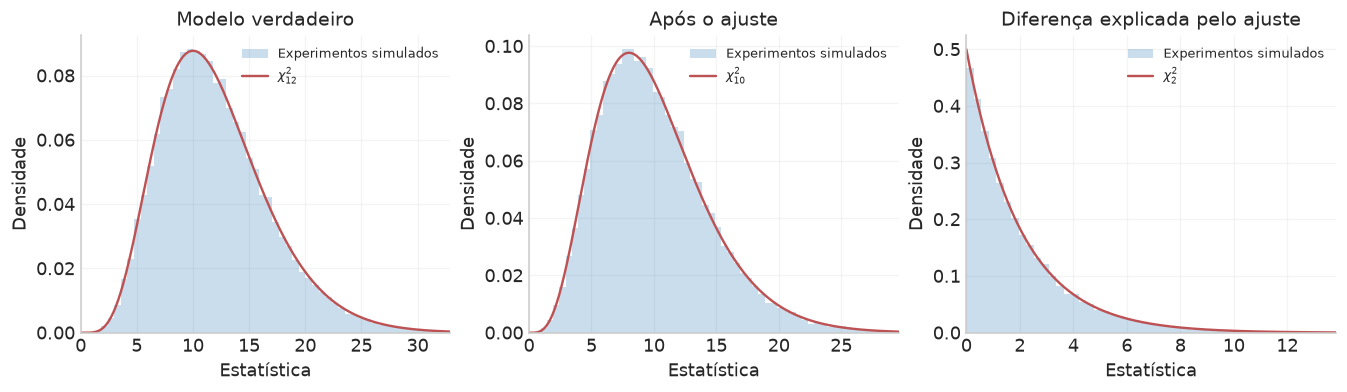

,Caso,Graus de liberdade,Média simulada,Variância simulada
0,Modelo verdadeiro,12,12.0033,23.7245
1,Após o ajuste,10,10.0223,19.8118
2,Diferença explicada pelo ajuste,2,1.9810,3.9204


In [10]:
# Repetir o experimento, ajustar e conferir as três leis.
rng_chi = np.random.default_rng(4010)
K = 45000
Z = rng_chi.normal(size=(K, len(x)))
H = cal['Gw']@C@cal['Gw'].T
Zaj = Z@H
q_verdadeiro = np.sum(Z**2, axis=1)
q_minimo = np.sum((Z-Zaj)**2, axis=1)
q_diferenca = np.sum(Zaj**2, axis=1)
verificar('Projetor simétrico e idempotente', np.allclose(H, H.T) and np.allclose(H@H, H))
verificar('Decomposição pitagórica do χ²', np.allclose(q_verdadeiro, q_minimo+q_diferenca))
fig, axs = plt.subplots(1, 3, figsize=(11.6, 3.3), constrained_layout=True)
registros=[]
for ax, vals, gl, titulo in zip(axs, [q_verdadeiro, q_minimo, q_diferenca],
                               [len(x), len(x)-2, 2],
                               ['Modelo verdadeiro', 'Após o ajuste', 'Diferença explicada pelo ajuste']):
    xx=np.linspace(0, stats.chi2.ppf(.999, gl), 500)
    ax.hist(vals, bins=80, density=True, color=AZUL, alpha=.25, label='Experimentos simulados')
    ax.plot(xx, stats.chi2.pdf(xx, gl), color=VERMELHO, label=fr'$\chi^2_{{{gl}}}$')
    ax.set(xlim=(0, xx[-1]), xlabel='Estatística', ylabel='Densidade', title=titulo);ax.legend(fontsize=8)
    registros.append({'Caso': titulo, 'Graus de liberdade': gl, 'Média simulada': vals.mean(), 'Variância simulada': vals.var()})
    verificar(f'Média amostral compatível: {titulo}', abs(vals.mean()-gl) < 6*np.sqrt(2*gl/K))
figura(fig, '07_tres_distribuicoes_chi2')
tabela(pd.DataFrame(registros), 'tres_chi2', casas=4)

## 6. Por que aparecem elipses e elipsoides?

A posterior gaussiana depende dos parâmetros somente por
$$
q=(\boldsymbol A-\widehat{\boldsymbol A})^TF(\boldsymbol A-\widehat{\boldsymbol A}),
\qquad F=C^{-1}=\Psi.
$$
Assim, $q=k$ é uma superfície de densidade constante. A matriz real simétrica e definida positiva $F$ admite uma base ortonormal de autovetores:
$$
F=O\Lambda O^T,\qquad O^TO=I,\quad
\Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_M),\quad\lambda_\alpha>0.
$$
As **colunas de $O$ indicam direções no espaço dos parâmetros**. Fazendo
$\delta\boldsymbol A=O\boldsymbol X$, ou $\boldsymbol X=O^T\delta\boldsymbol A$,
$$
q=\boldsymbol X^T\Lambda\boldsymbol X
=\sum_\alpha\lambda_\alpha X_\alpha^2.
$$
Portanto,
$$
\boxed{\sum_\alpha\frac{X_\alpha^2}{k/\lambda_\alpha}=1,
\qquad \ell_\alpha=\sqrt{\frac{k}{\lambda_\alpha}}.}
$$
Esta é a equação de um **elipsoide**; em duas dimensões, uma elipse. Os autovetores dão as direções dos eixos, e as raízes inversas dos autovalores de $F$ dão suas escalas. Se diagonalizarmos $C$, os autovalores serão $c_\alpha=1/\lambda_\alpha$ e os semieixos serão $\sqrt{k c_\alpha}$.

**Teorema dos eixos principais:** rotacionamos os eixos para acompanhar as direções naturais da distribuição. Nesse sistema, os termos mistos desaparecem. Para a gaussiana, as novas amplitudes $X_\alpha$ são independentes, com variâncias $1/\lambda_\alpha$. Um autovalor grande de Fisher significa que mover o parâmetro naquela direção muda rapidamente a likelihood: essa combinação está bem determinada. Um autovalor pequeno identifica uma direção de compensação entre parâmetros.

O sinal de cada autovetor pode ser invertido sem alterar o eixo físico. Os modos representam direções e suas escalas de incerteza, e a posição dos dados determina o centro da distribuição.

A rotação também permite normalizar a posterior: seu jacobiano em valor absoluto é 1 e
$$
\int_{\mathbb R^M}e^{-q/2}\,d^M A
=\prod_\alpha\int_{-\infty}^{\infty}e^{-\lambda_\alpha X_\alpha^2/2}dX_\alpha
=\frac{(2\pi)^{M/2}}{\sqrt{\prod_\alpha\lambda_\alpha}}
=\frac{(2\pi)^{M/2}}{\sqrt{\det F}}.
$$

### Qual elipse contém 68% ou 95%?

Rotacionar e reescalar por $Z_\alpha=\sqrt{\lambda_\alpha}X_\alpha$ produz $M$ normais padrão. Assim, $q=\sum Z_\alpha^2\sim\chi^2_M$ e
$$
P(q\leq k\mid\boldsymbol D)=F_{\chi^2_M}(k),
\qquad k=F_{\chi^2_M}^{-1}(P).
$$
O número de graus de liberdade aqui é a **dimensão da região**, inclusive depois de marginalizar. Em duas dimensões,
$$
P(q\leq k)=\int_0^{\sqrt{k}}e^{-r^2/2}r\,dr=1-e^{-k/2}.
$$
O fator $r$ é o jacobiano polar. Com $k=1$, a elipse contém $39{,}35\%$. Para conter os mesmos $68{,}27\%$ de um intervalo unidimensional de $\pm1\sigma$, precisamos de $k\simeq2{,}296$ e multiplicar os semieixos de $k=1$ por $\sqrt{k}\simeq1{,}515$.

Por isso convém indicar **a probabilidade conjunta e a dimensão**, em vez de usar apenas a expressão “elipse de um sigma”. Uma região de credibilidade contém massa da posterior. Uma região de confiança tem cobertura em experimentos repetidos; sob o modelo linear gaussiano com $E$ conhecida e prior plana, a mesma construção fornece ambas.

,Probabilidade (%),k em 1D,k em 2D,k em 3D,Multiplicador dos eixos em 2D
0,68.2689,1.0000,2.2957,3.5267,1.5152
1,90.0000,2.7055,4.6052,6.2514,2.1460
2,95.0000,3.8415,5.9915,7.8147,2.4477
3,95.4500,4.0000,6.1801,8.0249,2.4860
4,99.0000,6.6349,9.2103,11.3449,3.0349
5,99.7300,9.0000,11.8292,14.1564,3.4394


Massa da elipse q ≤ 1 em 2D: 39.3469%.


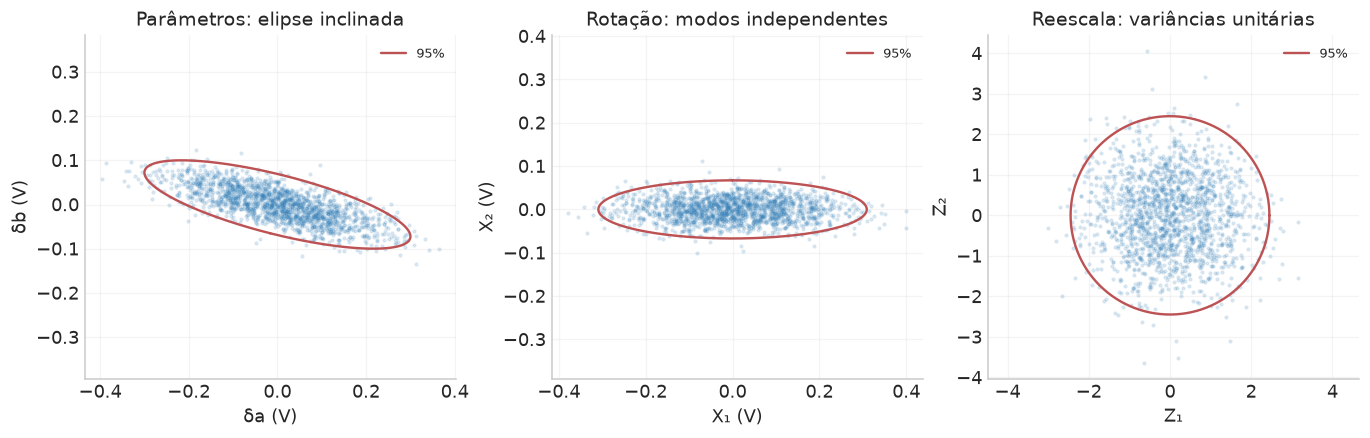

,Modo,Autovalor F (V⁻²),Componente em a,Componente em b,Desvio do modo (V),Semieixo 95% (V)
0,1,62.71833,-0.96941,0.24543,0.12627,0.30908
1,2,1331.12372,0.24543,0.96941,0.02741,0.06709


In [11]:
probs = [.682689492, .90, .95, .954499736, .99, .997300204]
tabela(pd.DataFrame({'Probabilidade (%)': 100*np.array(probs),
                     'k em 1D': stats.chi2.ppf(probs, 1),
                     'k em 2D': stats.chi2.ppf(probs, 2),
                     'k em 3D': stats.chi2.ppf(probs, 3),
                     'Multiplicador dos eixos em 2D': np.sqrt(stats.chi2.ppf(probs, 2))}),
       'limiares_regioes', casas=4)
print(f'Massa da elipse q ≤ 1 em 2D: {100*stats.chi2.cdf(1, 2):.4f}%.')

# Usamos a calibração: x adimensional faz a e b terem a mesma unidade (V).
lam, O = np.linalg.eigh(F)
verificar('Reconstrução espectral de Fisher', np.allclose(O@np.diag(lam)@O.T, F))
verificar('Covariância em eixos principais', np.allclose(O.T@C@O, np.diag(1/lam)))
rng_eixos = np.random.default_rng(5010)
am_A = rng_eixos.multivariate_normal(A_hat, C, 7000)
Xrot = (am_A-A_hat)@O
Zrot = Xrot*np.sqrt(lam)
q_am = np.einsum('ni,ij,nj->n', am_A-A_hat, F, am_A-A_hat)
verificar('Probabilidade conjunta recuperada em sorteios posteriores',
          abs(np.mean(q_am<=stats.chi2.ppf(.95, 2))-.95)<.012)
fig, axs = plt.subplots(1, 3, figsize=(11.8, 3.7), constrained_layout=True)
for ax, am, cov, title, labels in zip(axs, [am_A-A_hat, Xrot, Zrot],
        [C, np.diag(1/lam), np.eye(2)],
        ['Parâmetros: elipse inclinada', 'Rotação: modos independentes', 'Reescala: variâncias unitárias'],
        [('δa (V)', 'δb (V)'), ('X₁ (V)', 'X₂ (V)'), ('Z₁', 'Z₂')]):
    ax.scatter(am[::4, 0], am[::4, 1], s=3, color=AZUL, alpha=.13)
    desenhar_elipse(ax, [0, 0], cov, prob=.95, cor=VERMELHO, label='95%')
    ax.set(title=title, xlabel=labels[0], ylabel=labels[1]);ax.legend(fontsize=8)
# Aspecto igual nos painéis em que queremos comparar comprimentos geométricos.
axs[0].set_aspect('equal', adjustable='datalim');axs[1].set_aspect('equal', adjustable='datalim')
axs[2].set_aspect('equal', adjustable='datalim')
figura(fig, '08_eixos_principais_branqueamento')
tabela(pd.DataFrame({'Modo': [1, 2], 'Autovalor F (V⁻²)': lam,
                     'Componente em a': O[0], 'Componente em b': O[1],
                     'Desvio do modo (V)': 1/np.sqrt(lam),
                     'Semieixo 95% (V)': np.sqrt(stats.chi2.ppf(.95, 2)/lam)}), 'eixos_principais')

O modo largo permite variar uma combinação de intercepto e ganho mantendo previsões parecidas. A rotação identifica essa combinação; a reescala divide cada modo pelo seu próprio desvio padrão. A operação final deixa todas as direções comparáveis em unidades de incerteza.

No caso bidimensional, podemos abrir a fórmula dos semieixos usando
$$
C=\begin{pmatrix}s_a^2&c_{ab}\\c_{ab}&s_b^2\end{pmatrix},\qquad
\det(C-cI)=(s_a^2-c)(s_b^2-c)-c_{ab}^2=0.
$$
Resolver essa quadrática dá
$$
c_\pm=\frac{s_a^2+s_b^2}{2}
\pm\sqrt{\frac{(s_a^2-s_b^2)^2}{4}+c_{ab}^2}.
$$
Os semieixos da região de probabilidade $P$ são $\sqrt{k c_+}$ e $\sqrt{k c_-}$. O ângulo do eixo associado ao maior autovalor é
$\phi=\tfrac12\operatorname{atan2}(2c_{ab},s_a^2-s_b^2)$, entendido módulo $\pi$. Escrever $a^2,b^2$ para os autovalores, como nos slides, significa usar $a,b$ como **comprimentos básicos dos eixos**, em uma notação diferente dos nossos parâmetros da reta.

Esses resultados são exatos para a posterior gaussiana. Uma posterior multimodal, curvada ou cortada por uma borda física pode ter contornos de outras formas. Para modelos não lineares, a elipse geralmente é uma descrição **local**, que devemos conferir contra a posterior.

## 7. Marginalizar e fixar parâmetros: duas perguntas diferentes

Vamos dividir os parâmetros em $\boldsymbol u$, que queremos apresentar, e $\boldsymbol v$, que descreve os demais. Para uma gaussiana de média $(\mu_u,\mu_v)$, escrevemos os desvios e a precisão em blocos:
$$
F=\begin{pmatrix}K&B\\B^T&H\end{pmatrix},\qquad
q=\delta u^TK\delta u+2\delta u^TB\delta v+\delta v^TH\delta v.
$$
$K$ mede a curvatura em $u$ mantendo $v$ fixo; $H$, a curvatura em $v$; $B$, o acoplamento.

### 7.1 Marginalizar: somar sobre as possibilidades de $v$

A marginal é $p(u\mid D)=\int p(u,v\mid D)\,d v$. Completamos o quadrado em $\delta v$:
$$
q=(\delta v+H^{-1}B^T\delta u)^TH(\delta v+H^{-1}B^T\delta u)
+\delta u^T\underbrace{(K-BH^{-1}B^T)}_{F_{\rm marg}}\delta u.
$$
A integral do primeiro termo exponencial é $(2\pi)^{m_v/2}/\sqrt{\det H}$, independente de $u$. Logo,
$$
p(u\mid D)\propto
\exp[-\tfrac12\delta u^T(K-BH^{-1}B^T)\delta u],
\qquad C_{\rm marg}=(K-BH^{-1}B^T)^{-1}.
$$
Para conferir o bloco da inversa, escrevemos $FC=I$. Os blocos da primeira coluna dão
$$
KC_{uu}+BC_{vu}=I,\qquad B^TC_{uu}+HC_{vu}=0.
$$
A segunda equação implica $C_{vu}=-H^{-1}B^TC_{uu}$. Substituir na primeira produz
$$
(K-BH^{-1}B^T)C_{uu}=I
\quad\Rightarrow\quad
(F^{-1})_{uu}=C_{uu}=(K-BH^{-1}B^T)^{-1}.
$$
Portanto, **a covariância da marginal é o bloco $C_{uu}$ da covariância original**. Isso também vem da definição: calcular a variância de $u$ com a conjunta ou com sua marginal dá a mesma integral.

Este é o fundamento da regra dos slides: inverter $F$ para obter $C$, guardar as linhas e colunas dos parâmetros que ficam e, se quisermos uma Fisher reduzida, inverter esse bloco. Para encontrar diretamente a covariância marginal, basta conservar $C_{uu}$.

**Intuição:** cada valor de $u$ recebe contribuições de todos os $v$ que podem acompanhá-lo. As compensações permitidas por $v$ alargam a incerteza em $u$. Como $BH^{-1}B^T$ é semidefinida positiva, a curvatura marginal fica menor ou igual à curvatura $K$ com $v$ fixo.

### 7.2 Fixar: usar informação exata sobre $v$

Se fixarmos $v=\mu_v$, sobra $q=\delta u^TK\delta u$. Assim,
$$
\boxed{p(u\mid v=\mu_v,D)\text{ tem covariância }K^{-1}.}
$$
Agora conservamos o bloco **da precisão $F$**, ou removemos de $F$ as linhas e colunas dos parâmetros fixados. Essa regra é para uma gaussiana; em uma posterior geral, usamos a densidade condicional completa.

Fixar em outro valor $v_0$ conserva a covariância condicional $K^{-1}$, mas desloca a média:
$$
\mu_{u\mid v_0}=\mu_u-K^{-1}B(v_0-\mu_v).
$$
A operação condiciona em um valor exato; matematicamente uma condicional contínua é definida pela razão de densidades. Para a gaussiana, ela corresponde à forma do corte da conjunta em $v=v_0$, normalizada em $u$.

### 7.3 Abrindo tudo para a reta

Se
$$
C=\begin{pmatrix}s_a^2&\rho s_a s_b\\\rho s_a s_b&s_b^2\end{pmatrix},
\quad
F=\frac1{1-\rho^2}
\begin{pmatrix}s_a^{-2}&-\rho/(s_as_b)\\-\rho/(s_as_b)&s_b^{-2}\end{pmatrix},
$$
obtemos
$$
a\mid D\sim\mathcal N(\widehat a,s_a^2),\qquad
 a\mid b=\widehat b,D\sim\mathcal N(\widehat a,s_a^2(1-\rho^2)).
$$
Ao permitir que $b$ compense alterações de $a$, usamos o desvio $s_a$; ao conhecer $b$ exatamente, ele diminui para $s_a\sqrt{1-\rho^2}$. **$1/\sqrt{F_{aa}}$ é o erro condicional, enquanto $\sqrt{(F^{-1})_{aa}}$ é o erro marginal.**

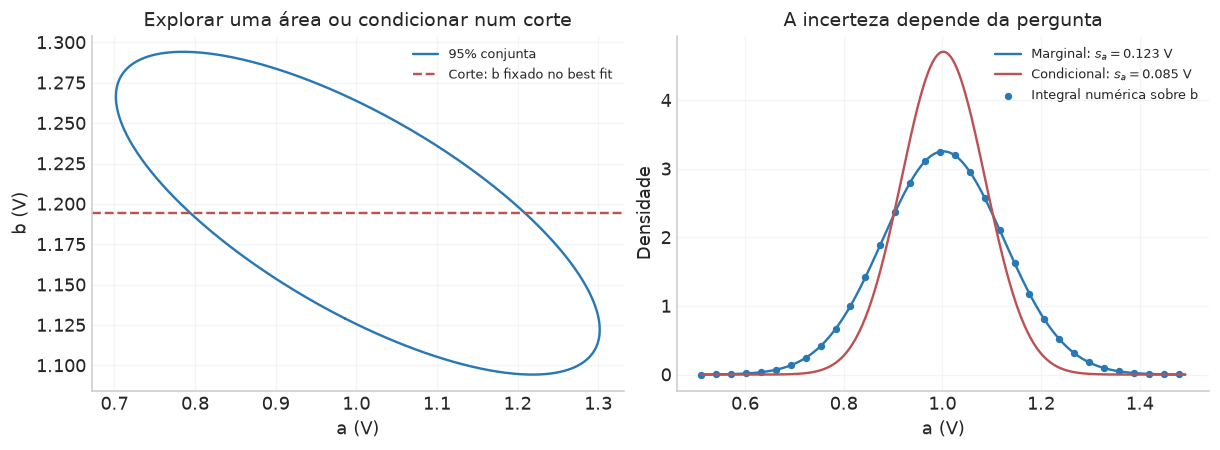

,Operação,Desvio de a (V),Precisão de a (V⁻²)
0,Marginalizar b,0.12259,66.53740
1,Fixar b no best fit,0.08478,139.12138


**Leitura da figura:** conhecer o ganho exatamente reduz o desvio do intercepto de **0.123 V** para **0.085 V**, uma redução de **30.8%**. A integral numérica da conjunta confirma a curva marginal mais larga.

In [12]:
sa, sb = np.sqrt(np.diag(C))
rho_ab = correlacao(C)[0,1]
s_a_fixo = 1/np.sqrt(F[0,0])
F_marg_a = F[0,0]-F[0,1]**2/F[1,1]
verificar('Schur: marginalizar b e conservar Caa', np.isclose(1/F_marg_a, C[0,0]))
verificar('Erro condicional da gaussiana bivariada', np.isclose(s_a_fixo, sa*np.sqrt(1-rho_ab**2)))
ag = np.linspace(A_hat[0]-4*sa, A_hat[0]+4*sa, 650)
# Quadratura explícita da conjunta sobre b: conferir a regra matricial.
p_conj = stats.multivariate_normal(mean=A_hat, cov=C)
p_integrada = np.array([integrate.quad(lambda b: p_conj.pdf([a,b]),
                            A_hat[1]-10*sb, A_hat[1]+10*sb, epsabs=1e-9)[0] for a in ag[::20]])
verificar('Marginalização por integral = gaussiana do bloco Caa',
          np.allclose(p_integrada, stats.norm.pdf(ag[::20], A_hat[0], sa), rtol=2e-6, atol=1e-8))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
desenhar_elipse(axs[0], A_hat, C, prob=.95, label='95% conjunta')
axs[0].axhline(A_hat[1], color=VERMELHO, ls='--', label='Corte: b fixado no best fit')
axs[0].set(xlabel='a (V)', ylabel='b (V)', title='Explorar uma área ou condicionar num corte')
axs[0].legend(fontsize=8)
axs[1].plot(ag, stats.norm.pdf(ag, A_hat[0], sa), color=AZUL, label=fr'Marginal: $s_a={sa:.3f}$ V')
axs[1].plot(ag, stats.norm.pdf(ag, A_hat[0], s_a_fixo), color=VERMELHO, label=fr'Condicional: $s_a={s_a_fixo:.3f}$ V')
axs[1].scatter(ag[::20], p_integrada, color=AZUL, s=13, label='Integral numérica sobre b')
axs[1].set(xlabel='a (V)', ylabel='Densidade', title='A incerteza depende da pergunta');axs[1].legend(fontsize=8)
figura(fig, '09_marginalizar_fixar')
tabela(pd.DataFrame({'Operação': ['Marginalizar b', 'Fixar b no best fit'],
                     'Desvio de a (V)': [sa, s_a_fixo],
                     'Precisão de a (V⁻²)': [F_marg_a, F[0,0]]}), 'marginal_condicional')
display(Markdown(f'**Leitura da figura:** conhecer o ganho exatamente reduz o desvio do intercepto de **{sa:.3f} V** para **{s_a_fixo:.3f} V**, uma redução de **{100*(1-s_a_fixo/sa):.1f}%**. A integral numérica da conjunta confirma a curva marginal mais larga.'))

### Mais parâmetros: o que um corner plot reúne?

Com três amplitudes, cada diagonal de um *corner plot* mostra uma marginal 1D; cada painel inferior mostra uma marginal 2D. Em cada caso conservamos o bloco correspondente de $C$. Uma marginal de dois parâmetros continua gaussiana e usa limiares de $\chi^2_2$, mesmo que o ajuste original tenha muitos parâmetros.

Vamos acrescentar um termo quadrático à calibração, usando um novo conjunto simulado. Esse exemplo mostra que uma coluna adicional de $G$ muda as compensações possíveis entre amplitudes.

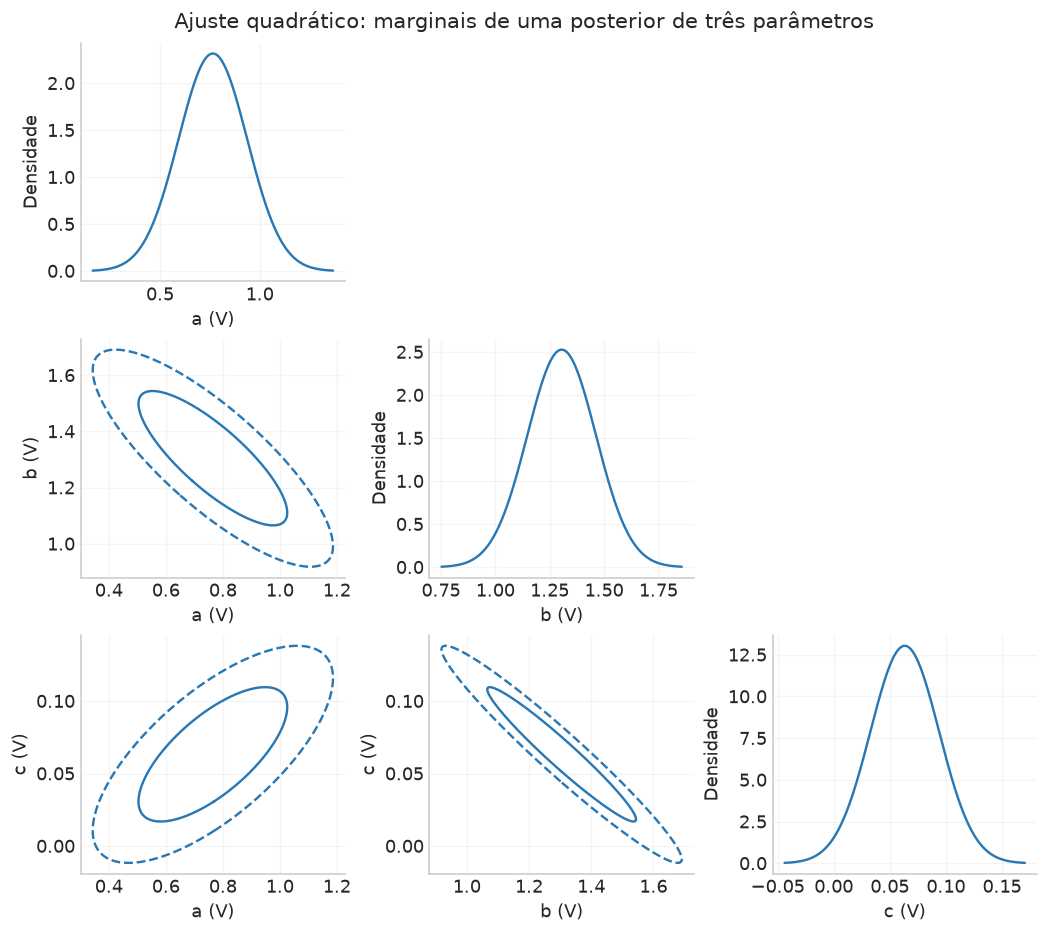

,a,b,c
a,1.00000,-0.81122,0.70208
b,-0.81122,1.00000,-0.96597
c,0.70208,-0.96597,1.00000


In [13]:
rng_quad = np.random.default_rng(6010)
G3 = np.column_stack([np.ones(x.size), x, x**2])
A3_real = np.array([.8, 1.25, .06])
d3 = G3@A3_real + L@rng_quad.normal(size=len(x))
quad = ajuste_linear(G3, d3, E)
mu3, C3, F3 = quad['A'], quad['C'], quad['F']
# Schur eliminando c: demonstração numérica em dimensão maior.
F3m = F3[:2,:2]-np.outer(F3[:2,2], F3[2,:2])/F3[2,2]
verificar('Schur 3D coincide com a inversa do bloco marginal',
          np.allclose(np.linalg.inv(F3m), C3[:2,:2]))
nomes = ['a (V)', 'b (V)', 'c (V)']
fig, axs = plt.subplots(3, 3, figsize=(9, 8), constrained_layout=True)
for i in range(3):
    for j in range(3):
        ax=axs[i,j]
        if j>i:
            ax.set_visible(False);continue
        if i==j:
            v=np.linspace(mu3[i]-3.5*np.sqrt(C3[i,i]), mu3[i]+3.5*np.sqrt(C3[i,i]), 400)
            ax.plot(v, stats.norm.pdf(v, mu3[i], np.sqrt(C3[i,i])), color=AZUL)
            ax.set_ylabel('Densidade')
        else:
            ind=[j,i]
            for p, st in [(.682689492, '-'), (.95, '--')]:
                desenhar_elipse(ax, mu3[ind], C3[np.ix_(ind,ind)], prob=p, ls=st)
            ax.set_ylabel(nomes[i])
        ax.set_xlabel(nomes[j])
fig.suptitle('Ajuste quadrático: marginais de uma posterior de três parâmetros', fontsize=13)
figura(fig, '10_corner_tres_parametros')
tabela(pd.DataFrame(correlacao(C3), index=['a','b','c'], columns=['a','b','c']), 'correlacoes_quadratico')

## 8. Acrescentar informação: novos dados e priors

### 8.1 Dois experimentos independentes

Se $D_1$ e $D_2$ são independentes **condicionalmente aos mesmos parâmetros**,
$\mathcal L_{12}(\boldsymbol A)=\mathcal L_1(\boldsymbol A)\mathcal L_2(\boldsymbol A)$.
Para duas likelihoods gaussianas nos parâmetros, de centros $\widehat A_1,\widehat A_2$ e precisões $F_1,F_2$, os expoentes somam:
$$
\begin{aligned}
-2\log\mathcal L_{12}
&=\boldsymbol A^T(F_1+F_2)\boldsymbol A
-2\boldsymbol A^T(F_1\widehat A_1+F_2\widehat A_2)+\text{constante},\\
\boxed{F_{12}=F_1+F_2,\qquad
\widehat A_{12}=F_{12}^{-1}(F_1\widehat A_1+F_2\widehat A_2).}
\end{aligned}
$$
A covariância combinada é $C_{12}=F_{12}^{-1}$. Duas elipses alongadas em direções diferentes podem produzir uma restrição muito menor: cada experimento resolve a compensação que o outro permite. A matriz sozinha descreve a precisão; o centro combinado requer também os centros individuais.

**Hipóteses da soma:** conjuntos condicionalmente independentes, mesma parametrização e mesma interpretação física dos parâmetros. Se compartilham uma referência incerta, sua covariância conjunta tem blocos cruzados; usar essa likelihood conjunta ou incluir o parâmetro compartilhado conserva a dependência. A soma de duas Fisher esperadas vale sob independência; somar curvaturas locais aproximadas pede avaliá-las no mesmo ponto de referência.

### 8.2 Uma prior gaussiana

Para $p(A)=\mathcal N(A_0,P)$, a multiplicação pela likelihood acrescenta o termo
$(A-A_0)^TP^{-1}(A-A_0)$. Completando o quadrado,
$$
\boxed{F_{\rm post}=F_L+F_{\rm prior},\qquad
F_{\rm prior}=P^{-1},\qquad
\mu_{\rm post}=F_{\rm post}^{-1}(F_L\widehat A_L+F_{\rm prior}A_0).}
$$
O máximo da posterior (*MAP*) pode se deslocar em relação ao máximo da likelihood (*ML*). A curvatura aumenta porque a prior traz informação adicional. Se só $b$ tem prior independente de desvio $s_{b,0}$, basta acrescentar $1/s_{b,0}^2$ ao elemento $bb$ da precisão; o vetor linear recebe $b_0/s_{b,0}^2$.

Ao combinar experimentos, contamos a prior **uma vez**:
$F_{\rm post}=F_{L,1}+F_{L,2}+F_{\rm prior}$.
Se partirmos de duas posteriores que já usam a mesma prior, somar suas precisões diretamente contaria essa informação duas vezes.

Quando $s_{b,0}\to0$, a prior concentra $b$ em $b_0$, e a posterior de $a$ converge à condicional $p(a\mid b=b_0,D)$. Quando $s_{b,0}$ é muito grande, sua curvatura local tende a zero. Uma uniforme larga também tem curvatura local nula no interior; suas bordas e sua normalização continuam relevantes em outros problemas.

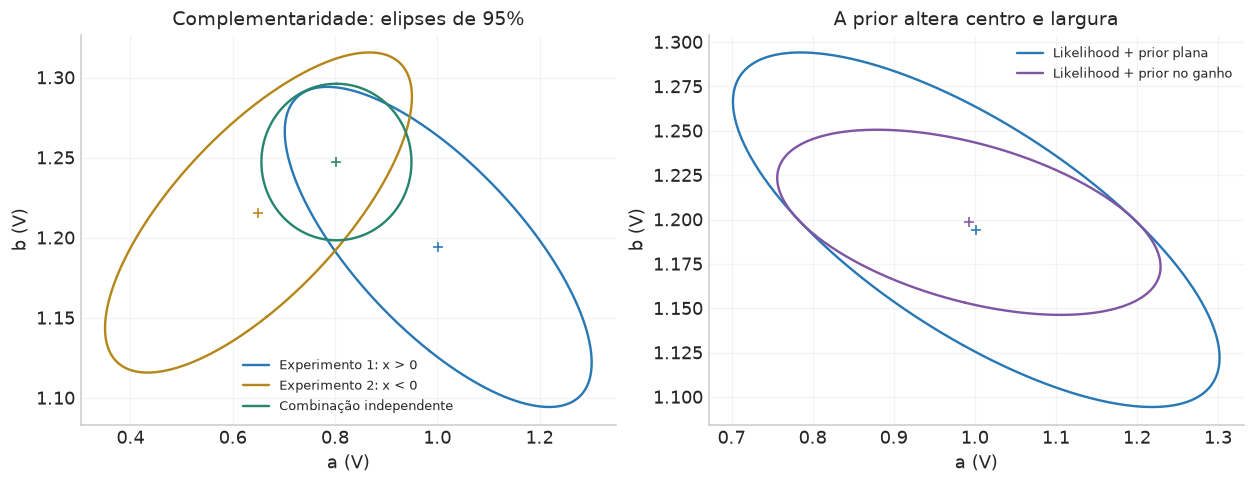

,Análise,a,b,sₐ,sᵦ,ρ
0,Experimento 1,1.00181,1.19424,0.12259,0.04082,-0.72231
1,Experimento 2,0.65034,1.21572,0.12259,0.04082,0.72231
2,Combinação,0.80277,1.24725,0.05995,0.01996,0.00000
3,Exp. 1 + prior,0.99272,1.19843,0.09657,0.02132,-0.47887


**Leitura da combinação:** a área da elipse conjunta cai para **34.6%** da área do experimento 1, no mesmo nível de probabilidade. Isso combina o ganho de dados com a complementaridade das direções. A prior no ganho reduz seu desvio marginal de **0.041 V** para **0.021 V** e desloca o centro em direção ao valor previamente favorecido.

In [14]:
# Um segundo instrumento independente mede a mesma reta em entradas negativas.
x2 = np.linspace(-5.1, -.3, 12)
G2 = np.column_stack([np.ones(x2.size), x2])
s2 = .15 + .025*np.abs(x2)
Eseg = np.diag(s2**2) + s_ref**2*np.ones((len(x2), len(x2)))
rng_seg = np.random.default_rng(7010)
d2 = G2@A_real + np.linalg.cholesky(Eseg)@rng_seg.normal(size=len(x2))
cal2 = ajuste_linear(G2, d2, Eseg)
F12 = F+cal2['F']; C12 = np.linalg.inv(F12)
A12 = np.linalg.solve(F12, F@A_hat+cal2['F']@cal2['A'])
# Resolver a likelihood conjunta em blocos deve dar o mesmo resultado.
conjunto = ajuste_linear(np.vstack([G,G2]), np.r_[d,d2], linalg.block_diag(E,Eseg))
verificar('Somar informações equivale ao ajuste conjunto independente',
          np.allclose(A12, conjunto['A']) and np.allclose(C12, conjunto['C']))

# Informação prévia independente sobre o ganho, usada apenas na calibração 1.
b0, sb0 = 1.20, .025
Fprior = np.diag([0., 1/sb0**2])
hprior = np.array([0., b0/sb0**2])
Fpost = F+Fprior; Cpost = np.linalg.inv(Fpost)
Apost = np.linalg.solve(Fpost, F@A_hat+hprior)
fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.1), constrained_layout=True)
for mu, cov, cor, lab in [(A_hat,C,AZUL,'Experimento 1: x > 0'),
                          (cal2['A'],cal2['C'],OURO,'Experimento 2: x < 0'),
                          (A12,C12,VERDE,'Combinação independente')]:
    desenhar_elipse(axs[0],mu,cov,cor=cor,prob=.95,label=lab)
    axs[0].plot(*mu,'+',color=cor)
for mu, cov, cor, lab in [(A_hat,C,AZUL,'Likelihood + prior plana'),
                          (Apost,Cpost,ROXO,'Likelihood + prior no ganho')]:
    desenhar_elipse(axs[1],mu,cov,cor=cor,prob=.95,label=lab)
    axs[1].plot(*mu,'+',color=cor)
for ax in axs:
    ax.set(xlabel='a (V)', ylabel='b (V)');ax.legend(fontsize=8)
axs[0].set_title('Complementaridade: elipses de 95%')
axs[1].set_title('A prior altera centro e largura')
figura(fig, '11_combinar_dados_prior')
reg=[]
for lab,mu,cov in [('Experimento 1',A_hat,C),('Experimento 2',cal2['A'],cal2['C']),
                   ('Combinação',A12,C12),('Exp. 1 + prior',Apost,Cpost)]:
    reg.append({'Análise':lab,'a':mu[0],'b':mu[1],'sₐ':np.sqrt(cov[0,0]),'sᵦ':np.sqrt(cov[1,1]),'ρ':correlacao(cov)[0,1]})
tabela(pd.DataFrame(reg),'combinacao_prior')
display(Markdown(f'**Leitura da combinação:** a área da elipse conjunta cai para **{100*np.sqrt(np.linalg.det(C12)/np.linalg.det(C)):.1f}%** da área do experimento 1, no mesmo nível de probabilidade. Isso combina o ganho de dados com a complementaridade das direções. A prior no ganho reduz seu desvio marginal de **{np.sqrt(C[1,1]):.3f} V** para **{np.sqrt(Cpost[1,1]):.3f} V** e desloca o centro em direção ao valor previamente favorecido.'))

In [15]:
# A prior estreita reproduz a condicional, incluindo o deslocamento da média.
mu_a_cond = A_hat[0] - F[0,1]/F[0,0]*(b0-A_hat[1])
lista_prior=[]
for spr in [1., .2, .06, .01, .001, .00001]:
    fp = F+np.diag([0., 1/spr**2])
    cp = np.linalg.inv(fp)
    mp = np.linalg.solve(fp, F@A_hat+np.array([0., b0/spr**2]))
    lista_prior.append({'Desvio da prior em b':spr,'Média posterior de a':mp[0],
                        'Desvio posterior de a':np.sqrt(cp[0,0]),'Desvio posterior de b':np.sqrt(cp[1,1])})
verificar('Prior estreita converge à média condicional', abs(mp[0]-mu_a_cond)<1e-6)
verificar('Prior estreita converge à variância condicional', abs(cp[0,0]-1/F[0,0])<1e-7)
tabela(pd.DataFrame(lista_prior),'limite_prior_estreita',casas=7)
print(f'Fixando b = {b0:.3f} V: a = {mu_a_cond:.6f} ± {s_a_fixo:.6f} V.')

,Desvio da prior em b,Média posterior de a,Desvio posterior de a,Desvio posterior de b
0,1.00000,1.001787,0.122540,0.040788
1,0.20000,1.001308,0.121308,0.039997
2,0.06000,0.997853,0.112018,0.033751
3,0.01000,0.990019,0.087361,0.009713
4,0.00100,0.989319,0.084810,0.001000
5,0.00001,0.989311,0.084782,0.000010


Fixando b = 1.200 V: a = 0.989311 ± 0.084782 V.


## 9. Mudar de variáveis: o que muda na informação?

Escolher novos parâmetros é mudar a maneira de descrever o mesmo conjunto de previsões. Uma boa escolha pode tornar o significado físico e as correlações mais claros.

### 9.1 Transformação afim: covariância e Fisher exatas

Se $\boldsymbol q=T\boldsymbol A+\boldsymbol c$, com $T$ constante e inversível,
$$
\mu_q=T\mu_A+\boldsymbol c,\qquad C_q=TC_AT^T.
$$
Definimos $J=\partial\boldsymbol A/\partial\boldsymbol q=T^{-1}$. Substituir $\delta A=J\delta q$ no expoente fornece
$$
\delta A^TF_A\delta A=\delta q^T(J^TF_AJ)\delta q,
\qquad\boxed{F_q=J^TF_AJ.}
$$
Os jacobianos das duas fórmulas têm **sentidos opostos**, de acordo com qual quantidade estamos transformando.

A densidade posterior também transforma com o elemento de volume:
$$
p_q(q\mid D)=p_A(A(q)\mid D)\,\left|\det\frac{\partial A}{\partial q}\right|.
$$
Para uma transformação afim, esse determinante é constante e a posterior continua gaussiana. Uma região e sua imagem têm exatamente a mesma probabilidade, embora comprimentos e áreas em coordenadas possam mudar. A likelihood transforma por composição, $\mathcal L(q)=\mathcal L(A(q))$, pois é densidade nos dados; o jacobiano paramétrico entra na posterior e na prior.

### 9.2 Um exemplo físico: trocar o intercepto pelo valor no centro das medidas

Escrevemos a mesma reta como
$$
f(x)=a+bx=\alpha+b(x-x_p),\qquad \alpha=a+bx_p.
$$
$\alpha$ é a previsão da calibração na entrada $x_p$. Para $\boldsymbol q=(\alpha,b)$,
$$
T=\begin{pmatrix}1&x_p\\0&1\end{pmatrix},\qquad
J=\begin{pmatrix}1&-x_p\\0&1\end{pmatrix}.
$$
Abrindo $C_q=TC_AT^T$,
$$
\operatorname{Var}(\alpha)=C_{aa}+2x_pC_{ab}+x_p^2C_{bb},
\quad\operatorname{Cov}(\alpha,b)=C_{ab}+x_pC_{bb}.
$$
Escolher $x_p=-C_{ab}/C_{bb}$ elimina essa covariância. A mesma escolha minimiza $\operatorname{Var}[f(x_p)]$, como vemos derivando a expressão em $x_p$. Geometricamente estamos descrevendo a altura da reta **onde ela é melhor medida**, em vez de extrapolar até uma origem distante.

Diretamente pelas funções de base, a ortogonalidade exige
$$
\boldsymbol1^TW(\boldsymbol x-x_p\boldsymbol1)=0
\quad\Rightarrow\quad
x_p=\frac{\boldsymbol1^TW\boldsymbol x}{\boldsymbol1^TW\boldsymbol1}.
$$
Com erros independentes isso vira a média ponderada $\sum w_ix_i/\sum w_i$. A nova parametrização conserva todas as previsões; o ganho permanece o mesmo e o erro da nova altura pode ficar menor porque ela corresponde a outra quantidade física.

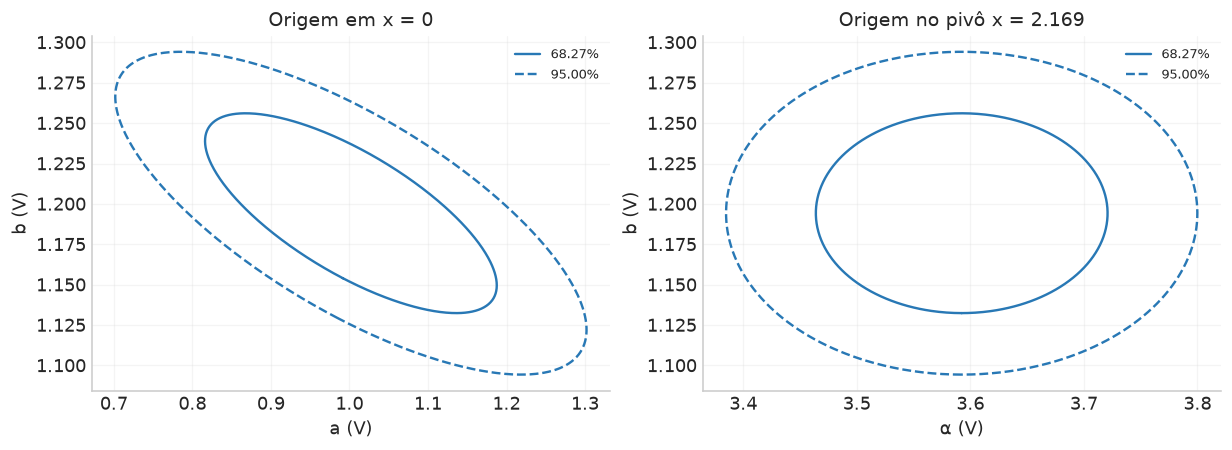

,Quantidade,Média,Desvio marginal
0,a = f(0),1.00181,0.12259
1,α = f(xₚ),3.59235,0.08478
2,b,1.19424,0.04082


**Leitura da mudança:** a altura no pivô tem desvio **0.085 V**, comparado com **0.123 V** na origem. O desvio do ganho permanece **0.041 V**. A altura mudou de definição; a reta prevista é a mesma em todos os pontos.

In [16]:
xp = -C[0,1]/C[1,1]
T = np.array([[1., xp],[0.,1.]])
J = np.array([[1., -xp],[0.,1.]])
mu_p = T@A_hat; Cp = T@C@T.T; Fp = J.T@F@J
Wp_x = linalg.solve(E,x,assume_a='pos')
Wp_1 = linalg.solve(E,np.ones(len(x)),assume_a='pos')
verificar('Pivô decorrelaciona as amplitudes', abs(Cp[0,1])<1e-12)
verificar('Pivô coincide com a ortogonalização da base', np.isclose(xp, Wp_x.sum()/Wp_1.sum()))
verificar('Transformações de C e F são consistentes',np.allclose(Cp@Fp,np.eye(2)))
G_piv = np.column_stack([np.ones(len(x)), x-xp])
cal_piv = ajuste_linear(G_piv,d,E)
verificar('Reajuste na base centrada conserva a posterior transformada',
          np.allclose(cal_piv['A'],mu_p) and np.allclose(cal_piv['C'],Cp))
verificar('Previsões preservadas ao mudar de parâmetros',np.allclose(G@A_hat,G_piv@mu_p))
fig,axs=plt.subplots(1,2,figsize=(10.6,3.8),constrained_layout=True)
for ax, mu, cov, xlabel, title in [(axs[0],A_hat,C,'a (V)','Origem em x = 0'),
                                  (axs[1],mu_p,Cp,'α (V)',f'Origem no pivô x = {xp:.3f}')]:
    for p,st in [(.682689492,'-'),(.95,'--')]:
        desenhar_elipse(ax,mu,cov,prob=p,ls=st,label=f'{100*p:.2f}%')
    ax.set(xlabel=xlabel,ylabel='b (V)',title=title);ax.legend(fontsize=8)
figura(fig,'12_mudanca_pivo')
tabela(pd.DataFrame({'Quantidade':['a = f(0)','α = f(xₚ)','b'],
                     'Média':[A_hat[0],mu_p[0],A_hat[1]],
                     'Desvio marginal':[sa,np.sqrt(Cp[0,0]),sb]}),'parametros_pivo')
display(Markdown(f'**Leitura da mudança:** a altura no pivô tem desvio **{np.sqrt(Cp[0,0]):.3f} V**, comparado com **{sa:.3f} V** na origem. O desvio do ganho permanece **{sb:.3f} V**. A altura mudou de definição; a reta prevista é a mesma em todos os pontos.'))

### 9.3 Transformações não lineares e parâmetros derivados

Para uma função suave $\boldsymbol q=h(\boldsymbol A)$, expandimos em torno de $\mu_A$:
$$
q_i\simeq h_i(\mu_A)+\sum_\alpha H_{i\alpha}(A_\alpha-\mu_\alpha),
\qquad H_{i\alpha}=\left.\frac{\partial h_i}{\partial A_\alpha}\right|_{\mu_A}.
$$
O termo constante desaparece da covariância; a média dos produtos dos termos lineares dá
$$
\boxed{C_q\simeq HC_AH^T.}
$$
A aproximação é boa quando o mapa varia quase linearmente sobre a região de probabilidade relevante. Se $H$ é retangular, a fórmula ainda propaga a incerteza para um conjunto de quantidades derivadas. Um mapa $M\to K<M$ agrega muitas possibilidades originais para o mesmo resultado: a distribuição exata é obtida pela posterior induzida, ou por transformar amostras.

Já uma matriz retangular $J=\partial A/\partial q$ em $F_q=J^TF_AJ$ descreve **um modelo restrito a uma subfamília** $A=A(q)$. São duas operações com sentidos diferentes: derivar quantidades da posterior e restringir os graus de liberdade do modelo. A marginalização continua sendo uma integração.

Um exemplo simples deixa visível o alcance da linearização. Se $u=\log r$ tem posterior $\mathcal N(\mu_u,s_u^2)$ e $r=e^u$, o jacobiano $du/dr=1/r$ dá
$$
p(r\mid D)=\frac{1}{r s_u\sqrt{2\pi}}
\exp\left[-\frac{(\log r-\mu_u)^2}{2s_u^2}\right],\qquad r>0.
$$
Essa é a lognormal. A propagação linear prevê $s_r\simeq e^{\mu_u}s_u$ e centro $r\simeq e^{\mu_u}$. A distribuição exata tem
$$
\operatorname{mediana}(r)=e^{\mu_u},\quad
\mathbb E[r]=e^{\mu_u+s_u^2/2},\quad
\operatorname{Var}(r)=(e^{s_u^2}-1)e^{2\mu_u+s_u^2},\quad
r_{\rm moda}=e^{\mu_u-s_u^2}.
$$
Esses momentos vêm de $\mathbb E[e^{t u}]=\exp(t\mu_u+t^2s_u^2/2)$, obtida completando o quadrado no expoente da normal. Um intervalo central exato se transforma pelos quantis:
$[e^{\mu_u-z_Ps_u},e^{\mu_u+z_Ps_u}]$, com $z_P=\Phi^{-1}((1+P)/2)$.
A probabilidade é conservada e o intervalo pode ficar assimétrico. Até a posição da moda depende das coordenadas usadas para a densidade.

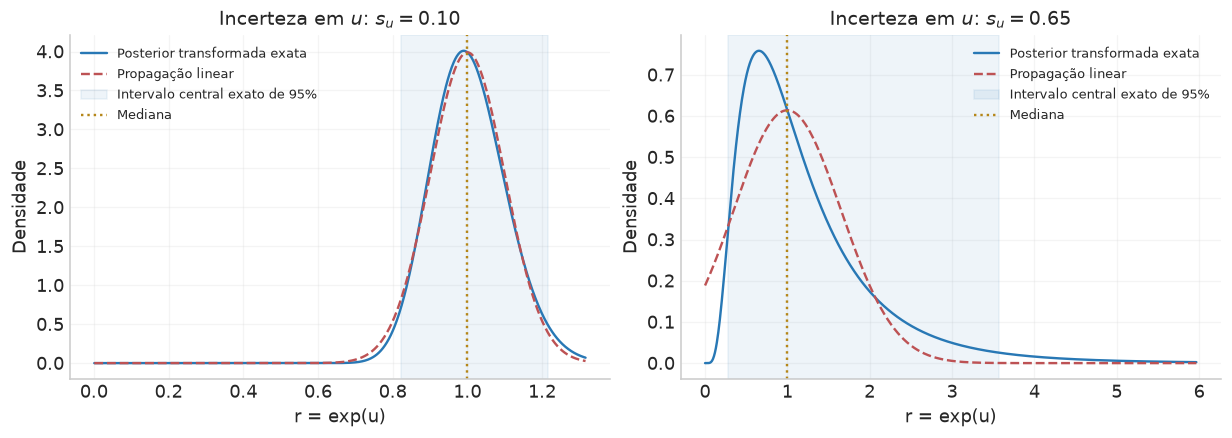

,sᵤ,Mediana r,Média r,Desvio exato,Desvio linear,IC95 inf.,IC95 sup.
0,0.10,1.0,1.00501,0.10075,0.10,0.82202,1.21652
1,0.65,1.0,1.23522,0.89566,0.65,0.27972,3.57504


In [17]:
mu_u=0.
fig,axs=plt.subplots(1,2,figsize=(10.6,3.7),constrained_layout=True)
regs=[]
for ax,su in zip(axs,[.10,.65]):
    dist=stats.lognorm(s=su,scale=np.exp(mu_u))
    rgrid=np.linspace(.001,dist.ppf(.997),1000)
    sd_linear=np.exp(mu_u)*su
    ax.plot(rgrid,dist.pdf(rgrid),color=AZUL,label='Posterior transformada exata')
    ax.plot(rgrid,stats.norm.pdf(rgrid,np.exp(mu_u),sd_linear),'--',color=VERMELHO,label='Propagação linear')
    lo,hi=dist.ppf([.025,.975])
    ax.axvspan(lo,hi,color=AZUL,alpha=.08,label='Intervalo central exato de 95%')
    ax.axvline(dist.median(),color=OURO,ls=':',label='Mediana')
    ax.set(xlabel='r = exp(u)',ylabel='Densidade',title=fr'Incerteza em $u$: $s_u={su:.2f}$')
    ax.legend(fontsize=8)
    regs.append({'sᵤ':su,'Mediana r':dist.median(),'Média r':dist.mean(),
                 'Desvio exato':dist.std(),'Desvio linear':sd_linear,'IC95 inf.':lo,'IC95 sup.':hi})
    verificar(f'Lognormal normalizada (s={su})',np.isclose(integrate.quad(dist.pdf,0,np.inf)[0],1.,atol=1e-8))
figura(fig,'13_transformacao_nao_linear')
tabela(pd.DataFrame(regs),'transformacao_log_normal')

## 10. Fisher como curvatura: do resultado exato à aproximação local

Até aqui o modelo é linear, $E$ é fixa e a posterior é gaussiana. Por isso $F=\Psi$ foi uma igualdade exata. Agora deixamos $f$ depender de parâmetros gerais $\boldsymbol\theta$.

Definimos $\ell(\theta)=\log p(\theta\mid D)$ e procuramos um máximo interior $\widehat\theta$ (*MAP*). A expansão de Taylor é
$$
\ell(\widehat\theta+\delta\theta)
=\ell(\widehat\theta)+\underbrace{\nabla\ell(\widehat\theta)^T\delta\theta}_{=0}
+\frac12\delta\theta^T[\nabla\nabla\ell]_{\widehat\theta}\delta\theta
+O(\|\delta\theta\|^3).
$$
Com
$$
\boxed{F_{\rm post}\equiv-[\nabla\nabla\log p(\theta\mid D)]_{\widehat\theta},}
$$
reter o termo quadrático e exponenciar fornece
$$
p(\theta\mid D)\simeq
\frac{\sqrt{\det F_{\rm post}}}{(2\pi)^{M/2}}
\exp[-\tfrac12\delta\theta^TF_{\rm post}\delta\theta],
\quad C\simeq F_{\rm post}^{-1}.
$$
A normalização acima é a da **aproximação gaussiana inteira**. A altura absoluta da posterior original no máximo pode diferir se os termos superiores contribuírem bastante à integral.

**Por que expandir o logaritmo?** Ele transforma produtos de fatores probabilísticos em somas, e a curvatura de uma parábola no logaritmo determina a largura da gaussiana. Podemos imaginar a paisagem de $-\log p$ como um potencial: perto de um mínimo regular, uma aproximação harmônica descreve pequenas flutuações. Direções de alta rigidez correspondem a incertezas menores. A analogia lembra os modos normais de oscilações acopladas.

### Como saber se a aproximação é apropriada?

Precisamos de um pico relevante, interior e suave, com curvatura definida positiva, e de termos cúbicos e superiores pequenos **na região que carrega a probabilidade**. Por exemplo, ao deslocar $\delta\theta$ por cerca de $F^{-1/2}\boldsymbol z$, com $z$ de ordem unitária, o termo cúbico deve ser pequeno frente ao quadrático. Um pico suave ou único, por si só, ainda permite caudas ou degenerescências curvas importantes.

Priors gaussianas entram pela soma de curvaturas; priors fortes ou com bordas também mudam o ponto de expansão e a forma global. Fisher calculada localmente descreve o entorno do pico. Para avaliar o alcance dessa descrição, podemos comparar cortes, contornos, integrais ou amostras da posterior completa.

### Abrindo a Hessiana da likelihood gaussiana

Com $E$ independente de $\theta$, escrevemos $r=D-f(\theta)$, $W=E^{-1}$ e $J_{i\alpha}=\partial f_i/\partial\theta_\alpha$. Como $\partial_\alpha r=-\partial_\alpha f$,
$$
\partial_\alpha\log\mathcal L=(\partial_\alpha f)^TWr.
$$
Derivando de novo,
$$
\boxed{(F_{L,\rm obs})_{\alpha\beta}
=-\partial_\alpha\partial_\beta\log\mathcal L
=(\partial_\alpha f)^TW(\partial_\beta f)
-\sum_i(Wr)_i\,\partial_\alpha\partial_\beta f_i.}
$$
O primeiro termo mede quanto as previsões mudam com os parâmetros; o segundo depende da curvatura do modelo e dos resíduos realizados. No caso linear, $J=G$ e as derivadas segundas de $f$ zeram, recuperando exatamente $G^TWG$.

Para uma prior gaussiana, $F_{\rm post}=F_{L,\rm obs}+P^{-1}$ no máximo posterior. Com prior plana e bordas distantes, MAP e ML coincidem. A expressão “Fisher bayesiana” dos slides se refere a essa curvatura local da log-posterior. Separá-la da informação esperada ajuda a interpretar as aproximações.

### Um exemplo em que a gaussiana local perde uma degenerescência curva

Considere duas medidas independentes $D=(0,0)$, com erros $(1,s)$, de um modelo
$$
f_1(u,v)=u,\qquad f_2(u,v)=v-\kappa u^2.
$$
Com prior plana, a posterior é própria:
$$
p(u,v\mid D)=\frac1{2\pi s}
\exp\left[-\frac12\left(u^2+\frac{(v-\kappa u^2)^2}{s^2}\right)\right].
$$
Isso pode ser verificado pela transformação $w=v-\kappa u^2$, cujo jacobiano vale 1: $u\sim\mathcal N(0,1)$ e $w\sim\mathcal N(0,s^2)$ independentes. O máximo é $(0,0)$ e a curvatura local é
$$
F_{\rm local}=\begin{pmatrix}1&0\\0&s^{-2}\end{pmatrix}.
$$
A aproximação gaussiana local usa $v\sim\mathcal N(0,s^2)$. Já a distribuição completa possui
$$
\mathbb E[v]=\kappa,\qquad
\operatorname{Var}(v)=s^2+2\kappa^2,\qquad\operatorname{Cov}(u,v)=0.
$$
Usamos $v=w+\kappa u^2$, $\mathbb E[u^2]=1$ e $\operatorname{Var}(u^2)=2$. A covariância cruzada zera porque $\mathbb E[u^3]=0$; a dependência quadrática permanece. Esse é também um exemplo concreto de variáveis dependentes e sem correlação linear.

Para $|\kappa|\ll s$, a curvatura da degenerescência é pequena sobre $|u|\lesssim1$ e a aproximação local funciona melhor. Quando $\kappa$ cresce, a posterior acompanha uma faixa curva, mesmo com máximo único. Este exemplo antecipa somente o alcance da aproximação; os métodos para explorar essas posteriores entram no próximo bloco do curso.

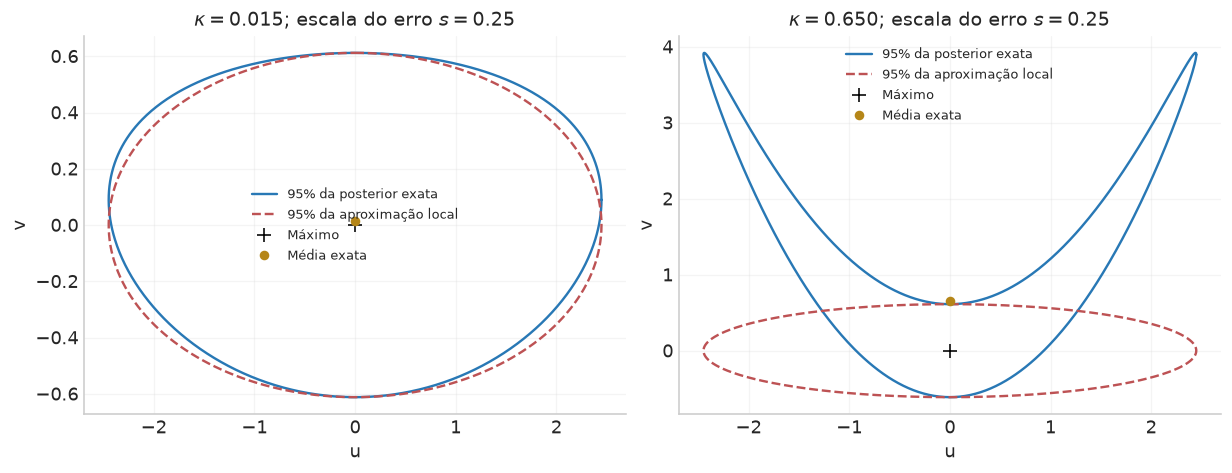

,κ,Média exata de v,Desvio exato de v,Desvio local de v
0,0.015,0.015,0.25090,0.25
1,0.650,0.650,0.95263,0.25


In [18]:
s_curva=.25
fig,axs=plt.subplots(1,2,figsize=(10.6,4),constrained_layout=True)
ang=np.linspace(0,2*np.pi,900)
k95=stats.chi2.ppf(.95,2)
ug=np.sqrt(k95)*np.cos(ang)
wg=s_curva*np.sqrt(k95)*np.sin(ang)
regs=[]
for ax,kap in zip(axs,[.015,.65]):
    vg=wg+kap*ug**2
    ax.plot(ug,vg,color=AZUL,label='95% da posterior exata')
    desenhar_elipse(ax,[0,0],np.diag([1.,s_curva**2]),prob=.95,cor=VERMELHO,ls='--',label='95% da aproximação local')
    ax.plot(0,0,'+',color='black',ms=9,label='Máximo')
    ax.plot(0,kap,'o',color=OURO,ms=5,label='Média exata')
    ax.set(xlabel='u',ylabel='v',title=fr'$\kappa={kap:.3f}$; escala do erro $s={s_curva:.2f}$')
    ax.legend(fontsize=8)
    regs.append({'κ':kap,'Média exata de v':kap,'Desvio exato de v':np.sqrt(s_curva**2+2*kap**2),
                 'Desvio local de v':s_curva})
figura(fig,'14_alcance_fisher_degenerescencia_curva')
tabela(pd.DataFrame(regs),'alcance_fisher')
# Conferência da Hessiana por diferenças finitas de -log p no máximo.
def hessiana_central(fun,p,h=1e-4):
    p=np.asarray(p,float);n=len(p);Hn=np.zeros((n,n));f0=fun(p)
    for i in range(n):
        ei=np.eye(n)[i]*h
        Hn[i,i]=(fun(p+ei)-2*f0+fun(p-ei))/h**2
        for j in range(i):
            ej=np.eye(n)[j]*h
            Hn[i,j]=Hn[j,i]=(fun(p+ei+ej)-fun(p+ei-ej)-fun(p-ei+ej)+fun(p-ei-ej))/(4*h**2)
    return Hn
nlogp=lambda t:.5*(t[0]**2+((t[1]-.65*t[0]**2)/s_curva)**2)
verificar('Hessiana local do exemplo curvo',np.allclose(hessiana_central(nlogp,[0.,0.]),np.diag([1.,1/s_curva**2]),atol=1e-6))

## 11. Fisher frequentista: informação média de um experimento

Na abordagem frequentista, a informação é definida para a distribuição dos **dados possíveis**, em um parâmetro fixo $\theta$. O *score* é
$$
s_\alpha(D;\theta)=\partial_\alpha\log\mathcal L(D\mid\theta).
$$
Sob condições que permitem trocar derivada e integral e manter suporte adequado,
$$
\mathbb E_\theta[s_\alpha]
=\int\partial_\alpha\mathcal L\,dD
=\partial_\alpha\int\mathcal L\,dD=0.
$$
Como
$\partial_\alpha\partial_\beta\log\mathcal L
=(\partial_\alpha\partial_\beta\mathcal L)/\mathcal L-s_\alpha s_\beta$,
$$
\boxed{\mathcal I_{\alpha\beta}(\theta)
=\mathbb E_\theta[s_\alpha s_\beta]
=-\mathbb E_\theta[\partial_\alpha\partial_\beta\log\mathcal L].}
$$
O termo com a segunda derivada da likelihood integra a zero pela normalização. A esperança usa todos os dados possíveis gerados naquele parâmetro; a curvatura observada usa o conjunto realizado.

Para a média gaussiana $f(\theta)$ e $E$ fixa, a esperança de $r$ é zero. Assim,
$$
\boxed{\mathcal I_{\alpha\beta}=(\partial_\alpha f)^TE^{-1}(\partial_\beta f)=J^TE^{-1}J.}
$$
Podemos obter a mesma expressão por $\mathbb E[ss^T]=J^TW\mathbb E[rr^T]WJ=J^TWJ$. No ajuste linear gaussiano com prior plana, Fisher esperada, precisão da likelihood e precisão da posterior coincidem. Com modelo não linear, as curvaturas observadas podem flutuar entre experimentos. Priors acrescentam informação à posterior, e uma covariância que depende dos parâmetros produz termos adicionais.

Em um *forecast*, escolhemos um parâmetro fiducial e avaliamos a informação esperada nesse modelo. Com $E$ fixa, avaliar a curvatura usando dados iguais à média fiducial zera o termo de resíduos e recupera $J^TE^{-1}J$. Dados simulados individuais continuam flutuando. A coincidência com a posterior pede também tratar a prior e verificar a aproximação local.

A desigualdade de **Cramér–Rao**, sob regularidade, estabelece
$$
\operatorname{Cov}_\theta(\widehat\theta)\succeq\mathcal I(\theta)^{-1}
$$
para estimadores não viesados. A diferença das matrizes é semidefinida positiva. No ajuste linear que estudamos, $\widehat A$ é não viesado e sua covariância é exatamente $\Psi^{-1}$: ele satura esse limite. Em modelos gerais, o limite informa o que um estimador não viesado pode alcançar; sua realização depende do problema e do estimador.

In [19]:
# Score em muitas realizações no ponto gerador: a média de ssᵀ recupera Fisher.
rng_score=np.random.default_rng(8010)
ruido=rng_score.normal(size=(70000,len(x)))@L.T
scores=linalg.solve(E,G,assume_a='pos')
scores=ruido@scores
I_mock=scores.T@scores/len(scores)
verificar('Fisher esperada via score reproduz GᵀE⁻¹G',
          np.linalg.norm(I_mock-F)/np.linalg.norm(F)<.025)
# As mesmas realizações mostram a covariância amostral do estimador eficiente.
A_repetidos=A_real+ruido@B.T
C_repetidos=np.cov(A_repetidos,rowvar=False)
verificar('Repetições do estimador eficiente recuperam F⁻¹',
          np.linalg.norm(C_repetidos-C)/np.linalg.norm(C)<.025)
tabela(pd.DataFrame({'Elemento':['aa','ab','bb'],
                     'Fisher analítica':[F[0,0],F[0,1],F[1,1]],
                     'Média dos produtos de scores':[I_mock[0,0],I_mock[0,1],I_mock[1,1]]}),
       'fisher_esperada_score')
tabela(pd.DataFrame({'Elemento':['aa','ab','bb'],
                     'Covariância posterior':[C[0,0],C[0,1],C[1,1]],
                     'Covariância entre ajustes':[C_repetidos[0,0],C_repetidos[0,1],C_repetidos[1,1]]}),
       'cramer_rao_linear')

,Elemento,Fisher analítica,Média dos produtos de scores
0,aa,139.12138,139.47933
1,ab,301.78240,302.20314
2,bb,1254.72067,1251.34806


,Elemento,Covariância posterior,Covariância entre ajustes
0,aa,0.01503,0.01502
1,ab,-0.00361,-0.00360
2,bb,0.00167,0.00166


## 12. Em que sentido Fisher é uma métrica?

O espaço dos dados e o espaço dos parâmetros têm papéis diferentes. No espaço dos dados, a matriz $E^{-1}$ mede a distância estatística entre dois vetores de médias:
$$
ds_D^2=\delta\boldsymbol f^TE^{-1}\delta\boldsymbol f.
$$
No espaço dos parâmetros, uma pequena variação produz
$\delta\boldsymbol f\simeq J\delta\boldsymbol\theta$. Substituindo,
$$
\boxed{ds^2=\delta\boldsymbol\theta^T\underbrace{(J^TE^{-1}J)}_{\mathcal I}\delta\boldsymbol\theta.}
$$
Fisher **transporta para os parâmetros a noção de distância estatística dos dados**. Um deslocamento curto em unidades físicas pode ser estatisticamente grande se mudar uma previsão muito precisa. Uma direção de degenerescência muda pouco as previsões e tem distância pequena.

A conexão com informação pode ser demonstrada pela divergência de Kullback–Leibler entre distribuições próximas dos dados:
$$
D_{\rm KL}[p(D\mid\theta)\,\|\,p(D\mid\theta+d\theta)]
=\mathbb E_\theta[\log\mathcal L(D\mid\theta)-\log\mathcal L(D\mid\theta+d\theta)].
$$
Expandimos o segundo logaritmo em $d\theta$. O termo linear tem esperança zero pela identidade do score. O termo quadrático usa $-\mathbb E[\partial_\alpha\partial_\beta\log\mathcal L]=\mathcal I_{\alpha\beta}$, resultando em
$$
D_{\rm KL}=\tfrac12d\theta^T\mathcal I\,d\theta+O(\|d\theta\|^3).
$$
Para gaussianas com mesma covariância e médias lineares nos parâmetros, essa relação é exata, sem os termos superiores. A informação esperada mede o quanto duas previsões probabilísticas próximas podem ser distinguidas. Se for definida positiva, ela fornece uma métrica local; direções não identificáveis podem torná-la somente semidefinida positiva.

Sob uma reparametrização suave inversível, o score transforma como $s_q=J^Ts_\theta$, com $J=\partial\theta/\partial q$. Portanto,
$$
\mathcal I_q=J^T\mathcal I_\theta J,
\quad d\theta^T\mathcal I_\theta d\theta=dq^T\mathcal I_q dq.
$$
A distância é a mesma nas duas descrições. Esta é a formulação geométrica precisa da analogia.

**Curvatura da posterior e coordenadas:** a Fisher esperada da likelihood tem essa lei tensorial exata. Uma densidade posterior muda também pelo jacobiano paramétrico. Em uma transformação não linear, a Hessiana de sua log-densidade pode receber termos do jacobiano, e a moda pode mudar. Usar $F_q\simeq J^TF_\theta J$ para a aproximação posterior pressupõe a linearização local e jacobiano aproximadamente constante na região relevante. O exemplo lognormal mostrou concretamente essa diferença.

In [20]:
# Uma mesma distância informacional antes e depois da troca para o pivô.
dA=np.array([.13,-.025]);dq=T@dA
mudanca_media=G@dA
q_dados=mudanca_media@linalg.solve(E,mudanca_media,assume_a='pos')
q_param=dA@F@dA
q_pivo=dq@Fp@dq
verificar('Métrica consistente nos dados e nas duas parametrizações',
          np.allclose([q_dados,q_param,q_pivo],q_dados))
tabela(pd.DataFrame({'Descrição':['Variação das previsões','Parâmetros (a,b)','Parâmetros (α,b)'],
                     'Distância estatística²':[q_dados,q_param,q_pivo],
                     'KL entre previsões gaussianas':[q_dados/2,q_param/2,q_pivo/2]}),'metrica_invariante')

,Descrição,Distância estatística²,KL entre previsões gaussianas
0,Variação das previsões,1.17377,0.58688
1,"Parâmetros (a,b)",1.17377,0.58688
2,"Parâmetros (α,b)",1.17377,0.58688


## 13. Determinante, hipervolume e desenho de experimentos

A região elipsoidal de probabilidade $P$ é
$\delta\theta^TF\delta\theta\leq k$, com $k=F^{-1}_{\chi^2_M}(P)$.
Na base principal, reescalamos $z_\alpha=\sqrt{\lambda_\alpha}X_\alpha$. A região vira uma bola de raio $\sqrt{k}$ e o elemento de volume transforma como
$$
d^M\theta=\prod_\alpha\frac{dz_\alpha}{\sqrt{\lambda_\alpha}}
=\frac{d^Mz}{\sqrt{\det F}}.
$$
A bola unitária em $M$ dimensões tem volume $V_M=\pi^{M/2}/\Gamma(M/2+1)$. Logo,
$$
\boxed{V(P)=\frac{\pi^{M/2}}{\Gamma(M/2+1)}
\frac{k^{M/2}}{\sqrt{\det F}}.}
$$
Em 2D, isso dá $\mathcal A(P)=\pi k/\sqrt{\det F}$, também obtida multiplicando os dois semieixos. Uma figura de mérito usual é
$$
\operatorname{FoM}=\sqrt{\det F},
$$
proporcional ao inverso do volume quando mantemos fixos a dimensão, o nível de probabilidade e as coordenadas/unidades. Como $\det F=\prod\lambda_\alpha$, uma direção muito pouco restrita aumenta o volume. Experimentos complementares podem reduzir justamente essa direção.

Se repetirmos $n$ vezes um experimento independente idêntico, $F_n=nF$, os desvios caem como $n^{-1/2}$ e $V_n\propto n^{-M/2}$. Uma referência incerta comum a todas as repetições exige modelar as correlações; sua contribuição pode persistir.

A FoM resume **tamanho**, enquanto os autovetores e autovalores também mostram orientação e forma. Duas regiões podem ter a mesma área e incertezas muito diferentes em um parâmetro específico. A FoM também deixa de fora o deslocamento dos centros: comparar compatibilidade entre experimentos requer olhar a posição das distribuições e suas hipóteses.

Uma mudança de unidade altera o volume numérico e a FoM. Para $\theta=Jq$ afim,
$\sqrt{\det F_q}=|\det J|\sqrt{\det F_\theta}$ e o volume se transforma com o jacobiano correspondente. Comparações de desenho experimental devem usar os mesmos parâmetros e convenções. O elemento geométrico $\sqrt{\det\mathcal I}\,d^M\theta$ é invariante sob reparametrizações regulares.

Autovalores e ângulos de eixos também dependem das escalas usadas nos parâmetros. Ao misturar parâmetros de unidades diferentes, uma escala de referência explícita permite interpretar as combinações. Diagonalizar uma covariância padronizada descreve os modos das variáveis padronizadas; diagonalizar a covariância física descreve os modos nas coordenadas físicas escolhidas.

,Análise,FoM (V⁻²),Área 95% (V²)
0,Experimento 1,288.93919,0.06514
1,Experimento 2,288.93919,0.06514
2,Combinação,835.60391,0.02253
3,Exp. 1 + prior,553.24503,0.03402


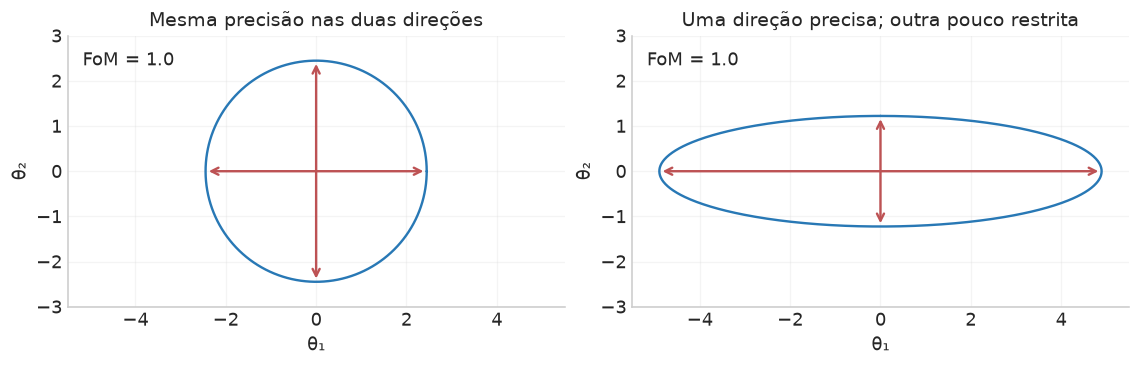

In [21]:
reg=[]
for lab,prec in [('Experimento 1',F),('Experimento 2',cal2['F']),('Combinação',F12),('Exp. 1 + prior',Fpost)]:
    fom=np.exp(.5*np.linalg.slogdet(prec)[1])
    area=np.pi*stats.chi2.ppf(.95,2)/fom
    reg.append({'Análise':lab,'FoM (V⁻²)':fom,'Área 95% (V²)':area})
tabela(pd.DataFrame(reg),'volume_fom')
# Mesma área: círculo e elipse muito alongada, nas mesmas coordenadas.
Cformas=[np.eye(2),np.diag([4.,.25])]
fig,axs=plt.subplots(1,2,figsize=(9.8,3.8),constrained_layout=True)
for ax,cf,titulo in zip(axs,Cformas,['Mesma precisão nas duas direções','Uma direção precisa; outra pouco restrita']):
    desenhar_elipse(ax,[0,0],cf,prob=.95,label='95% conjunta')
    vals,vec=np.linalg.eigh(cf)
    for i in range(2):
        ponta=np.sqrt(stats.chi2.ppf(.95,2)*vals[i])*vec[:,i]
        ax.annotate('',xy=ponta,xytext=-ponta,arrowprops={'arrowstyle':'<->','color':VERMELHO,'lw':1.5})
    ax.set(xlabel='θ₁',ylabel='θ₂',title=titulo,aspect='equal',xlim=(-5.5,5.5),ylim=(-3,3))
    ax.text(.03,.94,f'FoM = {1/np.sqrt(np.linalg.det(cf)):.1f}',transform=ax.transAxes,va='top')
figura(fig,'15_fom_mesmo_volume_formas')
verificar('Mesmo determinante permite formas diferentes',np.isclose(np.linalg.det(Cformas[0]),np.linalg.det(Cformas[1])))

## 14. Amarrando as operações

A mesma construção apareceu em linguagens diferentes. As funções de base dizem quais padrões procuramos; a covariância dos erros diz como pesar diferenças; o best fit projeta os dados nesses padrões; a posterior mostra o conjunto de amplitudes compatíveis com as hipóteses e as informações disponíveis. A geometria de Fisher organiza essa informação em direções bem ou mal determinadas.

| Pergunta | Operação na gaussiana | Interpretação |
|---|---|---|
| Qual o melhor ajuste linear? | Resolver $\Psi\widehat A=G^TE^{-1}D$ | Projetar os dados no espaço dos sinais |
| Qual a incerteza conjunta? | $C=\Psi^{-1}$, com prior plana | Inverter as curvaturas e conservar as compensações |
| Qual a marginal de um subconjunto? | Conservar o bloco correspondente de $C$ | Integrar os parâmetros restantes |
| Qual a incerteza com outros parâmetros conhecidos? | Conservar o bloco de $F$ e inverter | Usar uma condicional |
| Como combinar likelihoods independentes? | Somar precisões e vetores $F_i\mu_i$ | Acumular informação no mesmo espaço |
| Como incluir prior gaussiana? | Somar $P^{-1}$ e $P^{-1}\mu_0$ | Atualizar centro e curvatura |
| Como trocar de coordenadas afins? | $C_q=TC_\theta T^T$, $F_q=J^TF_\theta J$ | Descrever a mesma distribuição em outra base |
| Quais combinações são melhor medidas? | Diagonalizar $F$ ou $C$ | Encontrar os modos principais |
| Qual região contém probabilidade $P$? | $\delta\theta^TF\delta\theta\leq\chi^2_M{}^{-1}(P)$ | Escolher o raio pela dimensão correta |
| O que informa a FoM? | $\sqrt{\det F}$ | Precisão conjunta em coordenadas especificadas |

A igualdade $C=F^{-1}$ é exata na gaussiana. Para a curvatura local de uma posterior geral, ela representa a covariância **da aproximação gaussiana**, que pode diferir da covariância completa. A distinção entre dados gaussianos e parâmetros gaussianos também permanece: a primeira propriedade constrói a likelihood; a segunda depende ainda do modelo, da prior e da parametrização.